# Comet Tail - Solar Wind Interaction

## Spatial Convergence Analysis and Mass-Loading Effects in a Cometary MHD Simulation

### **Summary**



**Grid resolutions:** $256\times192$, $512\times384$, and $1024\times768$  
**Cases:** A (source off) and B (source on)  
**Physical output time:** $t=10$

Six two-dimensional MHD simulations of cometary interaction were evaluated: one case without a mass-loading source (A) and one with the source enabled (B), each computed at three grid resolutions. The `dbl.out` records show that all examined outputs correspond to the same physical time, $t=10$.

The main results obtained so far are:

- The full solutions show a reduction in RMSE between consecutive grids for density, velocity magnitude, magnetic-field magnitude, and pressure, in both A and B.
- The integrated density difference between B and A is `0.628318530718` at all three resolutions, consistent with the reported theoretical value `0.6283185307`.
- The scalar mass-loading effect does **not yet demonstrate grid independence**: the local RMSE between 512–1024 increases relative to 256–512 for density, velocity, and magnetic field.
- Errors are spatially concentrated. In the 512–1024 comparison, the 1% of cells with the largest errors accounts for between 68.84% and 93.86% of the sum of squared errors, depending on the variable.

### **Objective and Scope**

The objective is to evaluate how the numerical solutions change as the grid is refined and to determine whether the effect attributed to the mass-loading source remains spatially stable.

The analysis includes:

1. Comparison of the full solutions for cases A and B.
2. Comparison of the differential mass-source effect across resolutions.
3. Evaluation of the integrated density difference between the two cases.
4. Localization and quantification of the regions that dominate the error.

### **Numerical Setup**

#### Physical cases and directories

| Case | Meaning | Directories |
|---|---|---|
| A | Mass-loading source off | `Comet_NoSource`, `Comet_NoSource_512`, `Comet_NoSource_1024` |
| B | Mass-loading source on | `Comet_SolarWind`, `Comet_SolarWind_512`, `Comet_SolarWind_1024` |

According to the configuration reported during the work, the source parameter was `COMET_QM0 = 0` for A and `COMET_QM0 = 0.01` for B. The final input files should be archived together with the results to ensure traceability.

#### Resolutions and output time

| Simulation | Grid | Final time | Recorded steps |
|---|---:|---:|---:|
| A256 | 256 × 192 | 10.0 | 247 |
| B256 | 256 × 192 | 10.0 | 247 |
| A512 | 512 × 384 | 10.0 | 428 |
| B512 | 512 × 384 | 10.0 | 429 |
| A1024 | 1024 × 768 | 10.0 | 799 |
| B1024 | 1024 × 768 | 10.0 | 800 |

The number of steps may vary with cell size and the CFL condition. Matching the final physical time is more important than matching the number of time steps.

#### Initial conditions

In a previous check of A256 and B256 at the initial time (`nout=0`), the maximum differences in the compared variables and the grid coordinates were reported as zero. This initial-state check was documented for the base pair. The code in this notebook checks A/B geometric agreement at all three resolutions for the final outputs.

### **Methodology**

#### Analyzed quantities

The analysis uses density $\rho$, thermal pressure $p$, velocity magnitude, and magnetic-field magnitude:

$$
|\mathbf{v}|=\sqrt{v_x^2+v_y^2+v_z^2},\qquad
|\mathbf{B}|=\sqrt{B_x^2+B_y^2+B_z^2}.
$$

The components stored by PLUTO are used, including out-of-plane components when present.

#### Restriction from the fine grid to the coarse grid

To compare consecutive grids, the fine-grid solution is transferred to the coarse grid using block averaging over $2\times2$ cells:

$$
q^{\mathrm{fine}\rightarrow\mathrm{coarse}}_{i,j}
=\frac{1}{4}\sum_{a=0}^{1}\sum_{b=0}^{1}q^{\mathrm{fine}}_{2i+a,2j+b}.
$$

This procedure assumes a uniform Cartesian grid, equal cell areas, coincident domains, and nested/aligned grids. The code checks the 2:1 spacing ratio and cell-center alignment. If these conditions are not met, it stops to avoid an invalid comparison.

#### Error metrics

For coarse reference $q_c$, restricted fine solution $q_f$, and error $e=q_f-q_c$:

$$
\mathrm{MAE}=\frac{1}{N}\sum_{i,j}|e_{i,j}|,
\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{N}\sum_{i,j}e_{i,j}^2},
$$

$$
E_{L2,\mathrm{rel}}=100\,\frac{\mathrm{RMSE}}
{\sqrt{\frac{1}{N}\sum_{i,j}q_{c,i,j}^2}}\;\%.
$$

The relative error depends on the RMS norm of the selected reference. For the previously reported local percentage of the mass-loading effect, the denominator was the RMS norm of the restricted fine-grid effect. Therefore, percentages calculated with different denominators must be interpreted cautiously.

#### Differential mass-loading effect

For each resolution $h$, the scalar source effect is defined as:

$$
\Delta q_h=q_{B,h}-q_{A,h},
$$

for $q=\rho$, $|\mathbf{v}|$, and $|\mathbf{B}|$. This subtraction isolates the difference between configurations, but it is not equivalent to comparing the full perturbation vector: subtracting magnitudes can hide directional changes. A complementary analysis of the components $v_x,v_y,B_x,B_y$ is recommended.

#### Region of interest (ROI)

A preliminary region was used:

$$
0\leq x\leq7,\qquad -7\leq y\leq7.
$$

These limits were selected during the exploratory inspection of the maps. They should be justified using physical criteria before being presented as the definitive boundary of the interaction region.

### **Results for the Full Solutions**



#### Global RMSE

**Case A (source off):**

| Variable | 256–512 | 512–1024 |
|---|---:|---:|
| Density | 0.0528644 | 0.0306956 |
| Velocity magnitude | 0.00184670 | 0.00138855 |
| Magnetic-field magnitude | 0.00285075 | 0.00177111 |
| Thermal pressure | 0.00173321 | 0.00119805 |

**Case B (source on):**

| Variable | 256–512 | 512–1024 |
|---|---:|---:|
| Density | 0.0523758 | 0.0302714 |
| Velocity magnitude | 0.00187965 | 0.00133850 |
| Magnetic-field magnitude | 0.00281354 | 0.00174188 |
| Thermal pressure | 0.00171689 | 0.00118506 |

In all eight comparisons, the RMSE for 512–1024 is lower than for 256–512. This is a favorable trend, but the RMSE between two discretized solutions is not the error relative to an exact solution. By itself, it does not demonstrate grid independence.

The global relative errors also decreased. Case A: density 4.860% to 2.803%; velocity 0.1869% to 0.1405%; magnetic field 2.644% to 1.641%; pressure 3.120% to 2.153%. Case B: density 4.812% to 2.762%; velocity 0.1903% to 0.1355%; magnetic field 2.610% to 1.614%; pressure 3.081% to 2.124%.

The code generates `fig_rmse_global.png` to visualize these results.

### **Integrated Mass Balance**

The discrete integral of the density difference was calculated:

$
\Delta M_h=\sum_{i,j}(\rho_{B,h}-\rho_{A,h})_{i,j}\,\Delta x_h\,\Delta y_h.
$

| Resolution | Numerical value | Reported theoretical value |
|---|---:|---:|
| 256 × 192 | 0.628318530718 | 0.6283185307 |
| 512 × 384 | 0.628318530718 | 0.6283185307 |
| 1024 × 768 | 0.628318530718 | 0.6283185307 |

All three values agree, to the displayed precision, with the reported theoretical value. This is favorable for the consistency of the integrated additional mass between the configurations.

**Scope:** the integral of \(\rho_B-\rho_A\) is not, by itself, a complete global mass-conservation balance. Such a balance must also account for mass fluxes through the boundaries, source terms, and the time evolution of the mass contained in the domain. In a 2D Cartesian model, the integral may represent mass per unit depth, depending on the adopted normalization.

The code generates `fig_balance_masa.png`.

### **Convergence of the Mass-Loading Effect**



#### Global errors

| Variable | MAE 256–512 | MAE 512–1024 | RMSE 256–512 | RMSE 512–1024 |
|---|---:|---:|---:|---:|
| Density | 6.5699e-4 | 5.3270e-4 | 7.7882e-3 | 8.1120e-3 |
| Velocity | 7.2085e-5 | 6.3121e-5 | 1.1937e-3 | 1.4532e-3 |
| Magnetic field | 5.2958e-5 | 5.1162e-5 | 5.7951e-4 | 6.8920e-4 |

The global MAE decreases, while the global RMSE increases for all three variables. This suggests that the average absolute error is lower, but larger-amplitude discrepancies have greater weight in the sum of squares.

#### Results in the preliminary ROI

| Variable | Pair | MAE | RMSE | Relative error |
|---|---|---:|---:|---:|
| Density | 256–512 | 0.007872 | 0.027129 | 37.422% |
| Density | 512–1024 | 0.006395 | 0.028256 | 29.383% |
| Velocity | 256–512 | 0.000860 | 0.004158 | 32.721% |
| Velocity | 512–1024 | 0.000757 | 0.005063 | 30.503% |
| Magnetic field | 256–512 | 0.000633 | 0.002019 | 39.483% |
| Magnetic field | 512–1024 | 0.000617 | 0.002401 | 36.089% |

The local MAE decreases for all three variables, while the local RMSE increases by approximately 4.2% for density, 21.7% for velocity, and 18.9% for the magnetic field. Relative percentages decrease, but they use the RMS norm of the fine-grid effect and therefore do not negate the increase in absolute RMSE.

#### Apparent order: diagnostic, not a formal estimate

As a diagnostic, the following was calculated:

$
p_{\mathrm{app}}=\frac{\ln(E_{256-512}/E_{512-1024})}{\ln 2},
$

where \(E\) is the local RMSE of the differential effect. The reported values were:

| Variable | Apparent order |
|---|---:|
| Density | −0.059 |
| Velocity magnitude | −0.284 |
| Magnetic-field magnitude | −0.250 |

The negative values occur because the RMSE for 512–1024 is greater than for 256–512. They are not formal orders of the numerical method and should not be used to calculate a GCI: the sequence does not yet show a monotonic decrease in differences that would support inference of an asymptotic regime.

The code generates `fig_rmse_efecto_roi.png`.

### **Spatial Error Distribution**



#### Effect and error maps

The scalar fields $\Delta\rho$, $\Delta|\mathbf{v}|$, and $\Delta|\mathbf{B}|$ are compared. Error maps are defined as the restricted fine-grid effect minus the coarse-grid effect. Nearby bands of opposite signs may be consistent with local amplitude differences or small shifts in a structure; this hypothesis should be checked by overlaying the error maxima on the original physical fields.

The code generates:

- `fig_efectos_carga_masa.png`
- `fig_errores_efecto_256_512.png`
- `fig_errores_efecto_512_1024.png`

#### Absolute-error percentiles in the ROI

| Variable | Pair | P50 | P95 | P99 |
|---|---|---:|---:|---:|
| Density | 256–512 | 3.088e-4 | 0.039720 | 0.138752 |
| Density | 512–1024 | 6.325e-5 | 0.026796 | 0.153491 |
| Velocity | 256–512 | 4.447e-5 | 0.002277 | 0.021149 |
| Velocity | 512–1024 | 1.097e-5 | 0.001478 | 0.016964 |
| Magnetic field | 256–512 | 5.010e-5 | 0.003193 | 0.010290 |
| Magnetic field | 512–1024 | 2.047e-5 | 0.003025 | 0.011946 |

P50 and P95 decrease for all three variables. P99 decreases for velocity but increases for density and magnetic field. This indicates that a broad part of the distribution improves, while the extreme-discrepancy tail does not decrease uniformly.

#### Concentration of squared error

The percentage of the total sum of squared errors contributed by the cells with the largest absolute errors was:

| Variable | Pair | Top 1% | Top 0.1% |
|---|---|---:|---:|
| Density | 256–512 | 60.62% | 16.73% |
| Density | 512–1024 | 71.72% | 21.56% |
| Velocity | 256–512 | 81.62% | 25.78% |
| Velocity | 512–1024 | 93.86% | 31.41% |
| Magnetic field | 256–512 | 55.60% | 12.94% |
| Magnetic field | 512–1024 | 68.84% | 19.42% |

Error concentration is high and increases in the 512–1024 comparison for all three variables. For velocity, the 1% of cells with the largest errors contributes 93.86% of the sum of squared errors. This explains why MAE can decrease while RMSE increases.

#### Maximum errors in the ROI

| Variable | Pair | Maximum error | x | y |
|---|---|---:|---:|---:|
| Density | 256–512 | 0.324759 | 2.890625 | −0.078125 |
| Density | 512–1024 | 0.478349 | 2.929688 | −0.039062 |
| Velocity | 256–512 | 0.067327 | 1.171875 | −0.703125 |
| Velocity | 512–1024 | 0.094783 | 1.132812 | 0.429688 |
| Magnetic field | 256–512 | 0.021169 | 1.171875 | −0.546875 |
| Magnetic field | 512–1024 | 0.037201 | 1.210938 | 0.898438 |

In the magnetic-error coordinate CSV files that were shared, the main points appear in approximately symmetric pairs about $y=0$. For example, in 256–512 the same error 0.021169 was observed at $(1.171875,-0.546875)$ and $(1.171875,0.546875)$. For 512–1024, an error of 0.037201 was observed at $(1.210938,\pm0.898438)$. This is consistent with a symmetric distribution of these maxima, but it does not replace a symmetry test of all fields.

The CSV files generated by the notebook include the 1% of cells with the largest errors for density, velocity, and magnetic field in both comparisons. The concentration and location figures are `fig_concentracion_error.png` and `fig_localizacion_top_errores.png`.

### **Imports and Analysis Configuration**

The following cell defines the simulation paths, tolerances, ROI, and figure settings. Change the paths if the notebook is stored elsewhere.

In [24]:
from __future__ import annotations

import csv
import math
from pathlib import Path
from typing import Dict, Tuple, Any

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pyPLUTO as pp

# -----------------------------------------------------------------------------
# EDITABLE CONFIGURATION
# -----------------------------------------------------------------------------

BASE_DIR = Path(".")
FIG_DIR = BASE_DIR / "figuras_convergencia"
RESULT_DIR = BASE_DIR / "resultados_convergencia"
NOUT = 1

FOLDERS = {
    "A256": "Comet_NoSource",
    "B256": "Comet_SolarWind",
    "A512": "Comet_NoSource_512",
    "B512": "Comet_SolarWind_512",
    "A1024": "Comet_NoSource_1024",
    "B1024": "Comet_SolarWind_1024",
}

# Region of interest used in the exploratory analysis.
# Review and physically justify these limits before presenting them as
# the definitive boundary of the interaction region.
ROI = {"xmin": 0.0, "xmax": 7.0, "ymin": -7.0, "ymax": 7.0}

MASS_DIFFERENCE_THEORY = 0.6283185307
TIME_TOL = 1.0e-10
GRID_TOL = 1.0e-8

# Model normalized units: the units stored in the PLUTO files are retained.
VARIABLES = ["Densidad", "Magnitud de velocidad", "Magnitud del campo magnetico"]
VAR_KEYS = ["rho", "speed", "bmag"]
VAR_TEX = {
    "rho": r"$\rho$",
    "speed": r"$|\mathbf{v}|$",
    "bmag": r"$|\mathbf{B}|$",
    "prs": r"$p$",
}

plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
    "figure.titlesize": 12,
    "savefig.dpi": 220,
})

### **Loading Data, Validating Times and Geometry, and Restricting the Grid**


This cell loads `nout=1`, checks that the physical output time is common, validates A/B grid geometry, and verifies the uniform-grid and 2:1 refinement assumptions before block averaging.

In [25]:
# -----------------------------------------------------------------------------
# DATA LOADING AND VALIDATION
# -----------------------------------------------------------------------------

def read_output_time(folder: Path, nout: int) -> float:
    """Read the physical time from the nout record in dbl.out."""
    dbl_file = folder / "dbl.out"
    if not dbl_file.exists():
        raise FileNotFoundError(f"Could not find {dbl_file}")

    with dbl_file.open("r", encoding="utf-8", errors="replace") as stream:
        for line in stream:
            parts = line.split()
            if not parts:
                continue
            try:
                output_index = int(parts[0])
            except ValueError:
                continue
            if output_index == nout:
                if len(parts) < 2:
                    break
                return float(parts[1])

    raise ValueError(f"Could not find nout={nout} en {dbl_file}")


def load_all() -> Tuple[Dict[str, Any], Dict[str, float]]:
    data: Dict[str, Any] = {}
    times: Dict[str, float] = {}

    for name, relative_folder in FOLDERS.items():
        folder = BASE_DIR / relative_folder
        print(f"Loading {name}: {folder}")
        if not folder.exists():
            raise FileNotFoundError(
                f"Directory {folder} does not exist. Run the notebook from the parent directory of the simulation folders."
            )
        data[name] = pp.Load(nout=NOUT, path=str(folder))
        times[name] = read_output_time(folder, NOUT)
        print(f"  t = {times[name]:.12g}; shape rho = {data[name].rho.shape}")

    return data, times


def velocity_magnitude(D: Any) -> np.ndarray:
    return np.sqrt(D.vx1**2 + D.vx2**2 + D.vx3**2)


def magnetic_magnitude(D: Any) -> np.ndarray:
    return np.sqrt(D.Bx1**2 + D.Bx2**2 + D.Bx3**2)


def fields(D: Any) -> Dict[str, np.ndarray]:
    return {
        "rho": np.asarray(D.rho, dtype=float),
        "speed": np.asarray(velocity_magnitude(D), dtype=float),
        "bmag": np.asarray(magnetic_magnitude(D), dtype=float),
        "prs": np.asarray(D.prs, dtype=float),
    }


def validate_times(times: Dict[str, float]) -> None:
    values = np.array(list(times.values()), dtype=float)
    if not np.all(np.isfinite(values)):
        raise ValueError("Non-finite output times were found.")
    if np.max(values) - np.min(values) > TIME_TOL:
        detail = ", ".join(f"{k}={v:.12g}" for k, v in times.items())
        raise ValueError(
            "The simulations do not share the same physical time. "
            f"Tiempos: {detail}. Do not compare until the output times match."
        )
    print(f"Verified common physical time: t = {values[0]:.12g}")


def validate_same_grid(D1: Any, D2: Any, label: str) -> None:
    if D1.rho.shape != D2.rho.shape:
        raise ValueError(f"A/B dimensions differ in {label}")
    if not np.allclose(D1.x1, D2.x1, rtol=GRID_TOL, atol=GRID_TOL):
        raise ValueError(f"A/B x1 coordinates differ in {label}")
    if not np.allclose(D1.x2, D2.x2, rtol=GRID_TOL, atol=GRID_TOL):
        raise ValueError(f"A/B x2 coordinates differ in {label}")


def check_uniform_grid(D: Any, label: str) -> Tuple[float, float]:
    x = np.asarray(D.x1, dtype=float)
    y = np.asarray(D.x2, dtype=float)
    dx_all = np.diff(x)
    dy_all = np.diff(y)
    if len(dx_all) == 0 or len(dy_all) == 0:
        raise ValueError(f"Grid is too small in {label}")
    if not np.allclose(dx_all, dx_all[0], rtol=GRID_TOL, atol=GRID_TOL):
        raise ValueError(f"The x1 coordinate is not uniform in {label}")
    if not np.allclose(dy_all, dy_all[0], rtol=GRID_TOL, atol=GRID_TOL):
        raise ValueError(f"The x2 coordinate is not uniform in {label}")
    return float(dx_all[0]), float(dy_all[0])


def restrict_fine_to_coarse(
    fine_values: np.ndarray,
    fine_data: Any,
    coarse_data: Any,
    label: str = ""
) -> np.ndarray:
    """Restrict the fine grid to the coarse grid by 2x2 block averaging."""
    nx, ny = coarse_data.rho.shape
    expected = (2 * nx, 2 * ny)
    if fine_values.shape != expected:
        raise ValueError(
            f"Incompatible dimensions {label}: expected {expected}, "
            f"received {fine_values.shape}"
        )

    dx_c, dy_c = check_uniform_grid(coarse_data, f"coarse {label}")
    dx_f, dy_f = check_uniform_grid(fine_data, f"fine {label}")
    if not np.isclose(dx_c, 2.0 * dx_f, rtol=GRID_TOL, atol=GRID_TOL):
        raise ValueError(f"The x refinement is not 2:1 in {label}")
    if not np.isclose(dy_c, 2.0 * dy_f, rtol=GRID_TOL, atol=GRID_TOL):
        raise ValueError(f"The y refinement is not 2:1 in {label}")

    # For coordinates defined at cell centers, the centers of each pair of
    # fine cells must coincide with the center of the corresponding coarse cell.
    x_pair_centers = 0.5 * (fine_data.x1[0::2] + fine_data.x1[1::2])
    y_pair_centers = 0.5 * (fine_data.x2[0::2] + fine_data.x2[1::2])
    if not np.allclose(x_pair_centers, coarse_data.x1, rtol=GRID_TOL, atol=GRID_TOL):
        raise ValueError(f"Grid x-centers are not aligned in {label}")
    if not np.allclose(y_pair_centers, coarse_data.x2, rtol=GRID_TOL, atol=GRID_TOL):
        raise ValueError(f"Grid y-centers are not aligned in {label}")

    return fine_values.reshape(nx, 2, ny, 2).mean(axis=(1, 3))


def roi_mask(D: Any) -> np.ndarray:
    X, Y = np.meshgrid(D.x1, D.x2, indexing="ij")
    return (
        (X >= ROI["xmin"]) & (X <= ROI["xmax"]) &
        (Y >= ROI["ymin"]) & (Y <= ROI["ymax"])
    )

### **Metrics, Percentiles, Error Concentration, and CSV Export**

In [26]:
# -----------------------------------------------------------------------------
# METRICS AND EXPORT
# -----------------------------------------------------------------------------

def metrics(reference: np.ndarray, comparison: np.ndarray, mask: np.ndarray | None = None) -> Dict[str, float]:
    valid = np.isfinite(reference) & np.isfinite(comparison)
    if mask is not None:
        valid &= mask
    if not np.any(valid):
        raise ValueError("No valid cells are available for metric calculation")

    ref = reference[valid]
    comp = comparison[valid]
    error = comp - ref
    mae = float(np.mean(np.abs(error)))
    rmse = float(np.sqrt(np.mean(error**2)))
    rms_reference = float(np.sqrt(np.mean(ref**2)))
    rel = 100.0 * rmse / rms_reference if rms_reference > 0 else float("nan")
    return {"n": int(valid.sum()), "mae": mae, "rmse": rmse, "relative_l2_pct": rel}


def concentration_stats(error: np.ndarray, mask: np.ndarray) -> Dict[str, float]:
    valid = mask & np.isfinite(error)
    e = np.abs(error[valid])
    if e.size == 0:
        raise ValueError("ROI is empty for error-concentration analysis")
    sq = e**2
    total_sq = float(sq.sum())
    if total_sq == 0:
        top1 = top01 = 0.0
    else:
        n1 = max(1, int(math.ceil(0.01 * e.size)))
        n01 = max(1, int(math.ceil(0.001 * e.size)))
        top1 = 100.0 * float(np.sort(sq)[-n1:].sum()) / total_sq
        top01 = 100.0 * float(np.sort(sq)[-n01:].sum()) / total_sq

    return {
        "p50": float(np.percentile(e, 50)),
        "p95": float(np.percentile(e, 95)),
        "p99": float(np.percentile(e, 99)),
        "top1_sq_pct": top1,
        "top01_sq_pct": top01,
        "max_abs": float(np.max(e)),
    }


def save_dict_rows(path: Path, rows: list[dict]) -> None:
    if not rows:
        return
    keys = list(dict.fromkeys(k for row in rows for k in row.keys()))
    with path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=keys)
        writer.writeheader()
        writer.writerows(rows)


def save_top_errors(
    path: Path,
    error: np.ndarray,
    D: Any,
    mask: np.ndarray,
    fraction: float = 0.01,
) -> np.ndarray:
    ij = np.argwhere(mask & np.isfinite(error))
    vals = np.abs(error[mask & np.isfinite(error)])
    n_top = max(1, int(math.ceil(fraction * vals.size)))
    order = np.argsort(vals)[::-1][:n_top]
    selected_ij = ij[order]
    rows = np.column_stack((
        np.asarray(D.x1)[selected_ij[:, 0]],
        np.asarray(D.x2)[selected_ij[:, 1]],
        error[selected_ij[:, 0], selected_ij[:, 1]],
    ))
    np.savetxt(
        path,
        rows,
        delimiter=",",
        header="x,y,signed_error",
        comments="",
        fmt="%.12e",
    )
    return rows


def relative_apparent_order(e1: float, e2: float) -> float:
    """Diagnostic order; it is not interpreted as a formal order unless an asymptotic
    regime and monotonic decrease in differences are established."""
    if e1 <= 0 or e2 <= 0:
        return float("nan")
    return float(np.log(e1 / e2) / np.log(2.0))

### **Figure-Generation Functions**

In [31]:
# -----------------------------------------------------------------------------
# FIGURES
# -----------------------------------------------------------------------------

def save_effect_maps(effects: Dict[int, Dict[str, np.ndarray]], data: Dict[str, Any]) -> None:
    keys = ["rho", "speed", "bmag"]
    labels = [r"$\Delta\rho=\rho_B-\rho_A$", r"$\Delta |v|=|v|_B-|v|_A$", r"$\Delta |B|=|B|_B-|B|_A$"]
    resolutions = [256, 512, 1024]
    fig, axes = plt.subplots(3, 3, figsize=(13.5, 11.0), constrained_layout=True)

    for row, (key, label) in enumerate(zip(keys, labels)):
        vmax = max(float(np.nanmax(np.abs(effects[r][key]))) for r in resolutions)
        if vmax == 0:
            vmax = 1.0
        for col, res in enumerate(resolutions):
            D = data[f"A{res}"]
            ax = axes[row, col]
            im = ax.pcolormesh(
                D.x1, D.x2, effects[res][key].T,
                shading="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax
            )
            ax.set_title(f"{res} $\\times$ {int(res * 0.75)}")
            ax.set_xlabel("x")
            ax.set_ylabel("y")
            ax.set_aspect("equal", adjustable="box")
            fig.colorbar(im, ax=ax, shrink=0.82)
        axes[row, 0].text(-0.28, 0.5, label, transform=axes[row, 0].transAxes,
                          rotation=90, va="center", ha="center", fontsize=11)
    fig.suptitle("Scalar mass-loading effect by resolution")
    fig.savefig(FIG_DIR / "fig_efectos_carga_masa.png", bbox_inches="tight")
    plt.close(fig)


def save_error_maps(effect_comparisons: Dict[str, dict]) -> None:
    keys = ["rho", "speed", "bmag"]
    labels = [r"$\Delta\rho$", r"$\Delta |v|$", r"$\Delta |B|$"]
    pair_names = ["256-512", "512-1024"]
    vmax_by_key = {}
    for key in keys:
        vmax_by_key[key] = max(
            float(np.nanmax(np.abs(effect_comparisons[pair][key]["error"])))
            for pair in pair_names
        )
        if vmax_by_key[key] == 0:
            vmax_by_key[key] = 1.0

    for pair in pair_names:
        fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.8), constrained_layout=True)
        for ax, key, label in zip(axes, keys, labels):
            item = effect_comparisons[pair][key]
            D = item["coarse_data"]
            error = item["error"]
            vmax = vmax_by_key[key]
            im = ax.pcolormesh(
                D.x1, D.x2, error.T,
                shading="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax
            )
            ax.set_title(f"{label}: RMSE={item['global']['rmse']:.3e}")
            ax.set_xlabel("x")
            ax.set_ylabel("y")
            ax.set_aspect("equal", adjustable="box")
            fig.colorbar(im, ax=ax, label="error (restricted fine - coarse)")
        fig.suptitle(f"Mass-loading effect error: {pair.replace('-', ' vs ')}")
        fig.savefig(FIG_DIR / f"fig_errores_efecto_{pair.replace('-', '_')}.png", bbox_inches="tight")
        plt.close(fig)


def save_global_rmse_plot(global_rows: list[dict]) -> None:
    variables = ["rho", "speed", "bmag", "prs"]
    titles = [r"Density $\rho$", r"Velocity magnitude $|v|$", r"Magnetic field magnitude $|B|$", "Thermal pressure $p$"]
    pairs = ["256-512", "512-1024"]
    fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.5), constrained_layout=True)

    for ax, var, title in zip(axes.ravel(), variables, titles):
        for case, marker in [("A", "o"), ("B", "s")]:
            vals = []
            for pair in pairs:
                row = next(r for r in global_rows if r["kind"] == "full" and r["variable"] == var and r["case"] == case and r["pair"] == pair)
                vals.append(row["rmse"])
            ax.plot(pairs, vals, marker=marker, linewidth=1.8, label=f"Case {case}")
        ax.set_title(title)
        ax.set_ylabel("RMSE")
        ax.set_yscale("log")
        ax.grid(True, which="both", alpha=0.25)
        ax.legend()
    fig.suptitle("Difference between full solutions on consecutive grids")
    fig.savefig(FIG_DIR / "fig_rmse_global.png", bbox_inches="tight")
    plt.close(fig)


def save_roi_rmse_plot(effect_rows: list[dict]) -> None:
    vars_ = ["rho", "speed", "bmag"]
    titles = [r"Density $\Delta\rho$", r"Velocity $\Delta|v|$", r"Field $\Delta|B|$"]
    pairs = ["256-512", "512-1024"]
    fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.2), constrained_layout=True)
    for ax, var, title in zip(axes, vars_, titles):
        vals = []
        for pair in pairs:
            row = next(r for r in effect_rows if r["variable"] == var and r["pair"] == pair)
            vals.append(row["roi_rmse"])
        ax.bar(pairs, vals)
        ax.set_title(title)
        ax.set_ylabel("Local RMSE")
        ax.set_yscale("log")
        ax.grid(axis="y", which="both", alpha=0.25)
    fig.suptitle("Mass-loading effect RMSE in the preliminary ROI")
    fig.savefig(FIG_DIR / "fig_rmse_efecto_roi.png", bbox_inches="tight")
    plt.close(fig)


def save_concentration_plot(effect_rows: list[dict]) -> None:
    vars_ = ["rho", "speed", "bmag"]
    titles = ["Density", "Velocity", "Magnetic field"]
    pairs = ["256-512", "512-1024"]
    x = np.arange(len(pairs))
    width = 0.34
    fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.3), constrained_layout=True)
    for ax, var, title in zip(axes, vars_, titles):
        vals1, vals01 = [], []
        for pair in pairs:
            row = next(r for r in effect_rows if r["variable"] == var and r["pair"] == pair)
            vals1.append(row["top1_sq_pct"])
            vals01.append(row["top01_sq_pct"])
        ax.bar(x - width/2, vals1, width, label="Top 1%")
        ax.bar(x + width/2, vals01, width, label="Top 0.1%")
        ax.set_xticks(x, pairs)
        ax.set_ylim(0, 100)
        ax.set_ylabel("Contribution to squared error sum (%)")
        ax.set_title(title)
        ax.grid(axis="y", alpha=0.25)
        ax.legend()
    fig.suptitle("Spatial error concentration in the ROI")
    fig.savefig(FIG_DIR / "fig_concentracion_error.png", bbox_inches="tight")
    plt.close(fig)


def save_top_locations_plot(top_arrays: Dict[Tuple[str, str], np.ndarray]) -> None:
    keys = ["rho", "speed", "bmag"]
    titles = ["Density", "Velocity magnitude", "Magnetic field magnitude"]
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5), constrained_layout=True)
    for ax, key, title in zip(axes, keys, titles):
        for pair, marker in [("256-512", "o"), ("512-1024", "^")]:
            arr = top_arrays[(key, pair)]
            ax.scatter(arr[:, 0], arr[:, 1], s=13, alpha=0.65, marker=marker, label=pair)
        ax.axhline(0, linewidth=0.8, linestyle="--", alpha=0.6)
        ax.set_title(title)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_aspect("equal", adjustable="box")
        ax.legend(title="Comparison")
        ax.grid(alpha=0.2)
    fig.suptitle("Locations of the 1% of cells with the largest absolute errors")
    fig.savefig(FIG_DIR / "fig_localizacion_top_errores.png", bbox_inches="tight")
    plt.close(fig)


def save_mass_integral_plot(mass_rows: list[dict]) -> None:
    labels = [r["resolution"] for r in mass_rows]
    values = [r["integrated_mass_difference"] for r in mass_rows]
    fig, ax = plt.subplots(figsize=(7.2, 4.2), constrained_layout=True)
    ax.plot(labels, values, marker="o", linewidth=1.8, label="Numerical integral")
    ax.axhline(MASS_DIFFERENCE_THEORY, linestyle="--", linewidth=1.5,
               label=f"Theoretical value = {MASS_DIFFERENCE_THEORY:.10f}")
    ax.set_xlabel("Resolution")
    ax.set_ylabel(r"$\int (\rho_B-\rho_A)\,dA$")
    ax.set_title("Integrated mass difference")
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.grid(alpha=0.25)
    ax.legend()
    fig.savefig(FIG_DIR / "fig_balance_masa.png", bbox_inches="tight")
    plt.close(fig)

### **Run the Complete Analysis**

In [33]:
# -----------------------------------------------------------------------------
# PROGRAMA PRINCIPAL
# -----------------------------------------------------------------------------

def main() -> None:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    RESULT_DIR.mkdir(parents=True, exist_ok=True)

    data, times = load_all()
    validate_times(times)

    for name, D in data.items():
        print(f"{name}: shape={D.rho.shape}; dx,dy={check_uniform_grid(D, name)}")

    for res in (256, 512, 1024):
        validate_same_grid(data[f"A{res}"], data[f"B{res}"], f"resolucion {res}")

    field_data = {name: fields(D) for name, D in data.items()}

    # Scalar mass-loading effect: case B solution minus case A solution.
    effects: Dict[int, Dict[str, np.ndarray]] = {}
    for res in (256, 512, 1024):
        A = field_data[f"A{res}"]
        B = field_data[f"B{res}"]
        effects[res] = {
            "rho": B["rho"] - A["rho"],
            "speed": B["speed"] - A["speed"],
            "bmag": B["bmag"] - A["bmag"],
        }

    pairs = [(256, 512, "256-512"), (512, 1024, "512-1024")]
    global_rows: list[dict] = []
    effect_rows: list[dict] = []
    effect_comparisons: Dict[str, dict] = {}
    top_arrays: Dict[Tuple[str, str], np.ndarray] = {}

    # 1) Compare the full A and B solutions.
    print("\nCOMPARISON OF FULL SOLUTIONS")
    for coarse_res, fine_res, pair_name in pairs:
        coarse_D = data[f"A{coarse_res}"]
        fine_D = data[f"A{fine_res}"]
        for case in ("A", "B"):
            coarse_name = f"{case}{coarse_res}"
            fine_name = f"{case}{fine_res}"
            for var in ("rho", "speed", "bmag", "prs"):
                comp_fine = restrict_fine_to_coarse(
                    field_data[fine_name][var],
                    data[fine_name], data[coarse_name],
                    label=f"{case} {pair_name} {var}"
                )
                m = metrics(field_data[coarse_name][var], comp_fine)
                row = {
                    "kind": "full", "case": case, "pair": pair_name,
                    "variable": var, **m,
                }
                global_rows.append(row)
                print(f"Case {case} {pair_name} {var}: MAE={m['mae']:.8e}, "
                      f"RMSE={m['rmse']:.8e}, relL2={m['relative_l2_pct']:.5f}%")

    # 2) Compare the mass-loading effect over the full domain and within the ROI.
    print("\nCONVERGENCE OF THE MASS-LOADING EFFECT")
    for coarse_res, fine_res, pair_name in pairs:
        coarse_D = data[f"A{coarse_res}"]
        fine_D = data[f"A{fine_res}"]
        mask = roi_mask(coarse_D)
        effect_comparisons[pair_name] = {}

        for var in ("rho", "speed", "bmag"):
            fine_restricted = restrict_fine_to_coarse(
                effects[fine_res][var], fine_D, coarse_D,
                label=f"efecto {pair_name} {var}"
            )
            error = fine_restricted - effects[coarse_res][var]
            global_m = metrics(effects[coarse_res][var], fine_restricted)
            local_m = metrics(effects[coarse_res][var], fine_restricted, mask)
            # In the previous local analysis, the relative percentage was normalized
            # by the RMS of the restricted fine-grid effect.
            fine_effect_roi = fine_restricted[mask & np.isfinite(fine_restricted)]
            fine_effect_rms = float(np.sqrt(np.mean(fine_effect_roi**2)))
            local_m["relative_l2_pct"] = (
                100.0 * local_m["rmse"] / fine_effect_rms
                if fine_effect_rms > 0 else float("nan")
            )
            concentration = concentration_stats(error, mask)

            valid_roi = mask & np.isfinite(error)
            ij = np.argwhere(valid_roi)
            flat_abs = np.abs(error[valid_roi])
            kmax = int(np.argmax(flat_abs))
            i_max, j_max = ij[kmax]
            x_max = float(coarse_D.x1[i_max])
            y_max = float(coarse_D.x2[j_max])

            key = var
            effect_comparisons[pair_name][key] = {
                "error": error,
                "coarse_data": coarse_D,
                "global": global_m,
                "local": local_m,
                "concentration": concentration,
            }

            csv_name = f"top_errors_{var}_{pair_name.replace('-', '_')}.csv"
            top = save_top_errors(RESULT_DIR / csv_name, error, coarse_D, mask, 0.01)
            top_arrays[(var, pair_name)] = top

            row = {
                "variable": var, "pair": pair_name,
                "global_mae": global_m["mae"], "global_rmse": global_m["rmse"],
                "global_relative_l2_pct": global_m["relative_l2_pct"],
                "roi_mae": local_m["mae"], "roi_rmse": local_m["rmse"],
                "roi_relative_l2_pct": local_m["relative_l2_pct"],
                "p50": concentration["p50"], "p95": concentration["p95"],
                "p99": concentration["p99"],
                "top1_sq_pct": concentration["top1_sq_pct"],
                "top01_sq_pct": concentration["top01_sq_pct"],
                "max_abs_roi": concentration["max_abs"],
                "max_x": x_max, "max_y": y_max,
                "roi_cells": local_m["n"],
            }
            effect_rows.append(row)

            print(f"\n{var}, {pair_name}")
            print(f"  global MAE={global_m['mae']:.8e}, RMSE={global_m['rmse']:.8e}, "
                  f"relL2={global_m['relative_l2_pct']:.5f}%")
            print(f"  ROI MAE={local_m['mae']:.8e}, RMSE={local_m['rmse']:.8e}, "
                  f"relL2={local_m['relative_l2_pct']:.5f}%")
            print(f"  P50={concentration['p50']:.8e}, P95={concentration['p95']:.8e}, "
                  f"P99={concentration['p99']:.8e}")
            print(f"  Top 1%={concentration['top1_sq_pct']:.2f}%, "
                  f"Top 0.1%={concentration['top01_sq_pct']:.2f}%")
            print(f"  Max ROI={concentration['max_abs']:.8e} at ({x_max:.6f}, {y_max:.6f})")
            print(f"  CSV: {RESULT_DIR / csv_name}")

    # 3) Integrated mass difference at each resolution (uniform Cartesian grid).
    mass_rows: list[dict] = []
    print("\nINTEGRATED MASS DIFFERENCE")
    for res in (256, 512, 1024):
        A = data[f"A{res}"]
        B = data[f"B{res}"]
        dx, dy = check_uniform_grid(B, f"B{res}")
        value = float(np.sum(B.rho - A.rho) * dx * dy)
        rel_to_theory = 100.0 * abs(value - MASS_DIFFERENCE_THEORY) / abs(MASS_DIFFERENCE_THEORY)
        row = {
            "resolution": f"{res}x{int(res*0.75)}",
            "integrated_mass_difference": value,
            "theoretical_value": MASS_DIFFERENCE_THEORY,
            "relative_difference_pct": rel_to_theory,
        }
        mass_rows.append(row)
        print(f"{row['resolution']}: {value:.12f}; relative difference vs. theory={rel_to_theory:.4e}%")

    # 4) Apparent-order diagnostic for local RMSE (not a formal GCI).
    apparent_rows = []
    for var in ("rho", "speed", "bmag"):
        e1 = next(r["roi_rmse"] for r in effect_rows if r["variable"] == var and r["pair"] == "256-512")
        e2 = next(r["roi_rmse"] for r in effect_rows if r["variable"] == var and r["pair"] == "512-1024")
        p = relative_apparent_order(e1, e2)
        apparent_rows.append({"variable": var, "rmse_256_512": e1, "rmse_512_1024": e2, "diagnostic_apparent_order": p})

    # Export tables.
    save_dict_rows(RESULT_DIR / "metricas_soluciones_completas.csv", global_rows)
    save_dict_rows(RESULT_DIR / "metricas_efecto_carga_masa.csv", effect_rows)
    save_dict_rows(RESULT_DIR / "balance_masa.csv", mass_rows)
    save_dict_rows(RESULT_DIR / "orden_aparente_diagnostico.csv", apparent_rows)
    save_dict_rows(RESULT_DIR / "tiempos_salida.csv", [
        {"simulation": k, "time": v} for k, v in times.items()
    ])

    # Figures para el documento LaTeX.
    save_effect_maps(effects, data)
    save_error_maps(effect_comparisons)
    save_global_rmse_plot(global_rows)
    save_roi_rmse_plot(effect_rows)
    save_concentration_plot(effect_rows)
    save_top_locations_plot(top_arrays)
    save_mass_integral_plot(mass_rows)

    print("\nAPPARENT ORDER DIAGNOSTIC (interpret cautiously)")
    for row in apparent_rows:
        print(f"{row['variable']}: p_aparente={row['diagnostic_apparent_order']:.4f}")

    print("\nANALYSIS COMPLETED")
    print(f"Figures: {FIG_DIR.resolve()}")
    print(f"CSV tables: {RESULT_DIR.resolve()}")
    print("The apparent order is neither a GCI nor a formal convergence demonstration.")

In [34]:
main()

Loading A256: Comet_NoSource
Load: folder Comet_NoSource,     output 1
  t = 10; shape rho = (256, 192)
Loading B256: Comet_SolarWind
Load: folder Comet_SolarWind,     output 1
  t = 10; shape rho = (256, 192)
Loading A512: Comet_NoSource_512
Load: folder Comet_NoSource_512,     output 1


  t = 10; shape rho = (512, 384)
Loading B512: Comet_SolarWind_512
Load: folder Comet_SolarWind_512,     output 1
  t = 10; shape rho = (512, 384)
Loading A1024: Comet_NoSource_1024
Load: folder Comet_NoSource_1024,     output 1
  t = 10; shape rho = (1024, 768)
Loading B1024: Comet_SolarWind_1024
Load: folder Comet_SolarWind_1024,     output 1
  t = 10; shape rho = (1024, 768)
Verified common physical time: t = 10
A256: shape=(256, 192); dx,dy=(0.15625, 0.15625)
B256: shape=(256, 192); dx,dy=(0.15625, 0.15625)
A512: shape=(512, 384); dx,dy=(0.078125, 0.078125)
B512: shape=(512, 384); dx,dy=(0.078125, 0.078125)
A1024: shape=(1024, 768); dx,dy=(0.0390625, 0.0390625)
B1024: shape=(1024, 768); dx,dy=(0.0390625, 0.0390625)

COMPARISON OF FULL SOLUTIONS
Case A 256-512 rho: MAE=4.24140619e-03, RMSE=5.28643646e-02, relL2=4.86005%
Case A 256-512 speed: MAE=2.43305813e-04, RMSE=1.84670491e-03, relL2=0.18693%
Case A 256-512 bmag: MAE=2.99986836e-04, RMSE=2.85075000e-03, relL2=2.64422%
Case A 256

### **Display the Generated Figures in the Section**

Run this cell after the main analysis cell to display the PNG figures. The images are also saved in `figuras_convergencia/`.

fig_efectos_carga_masa.png


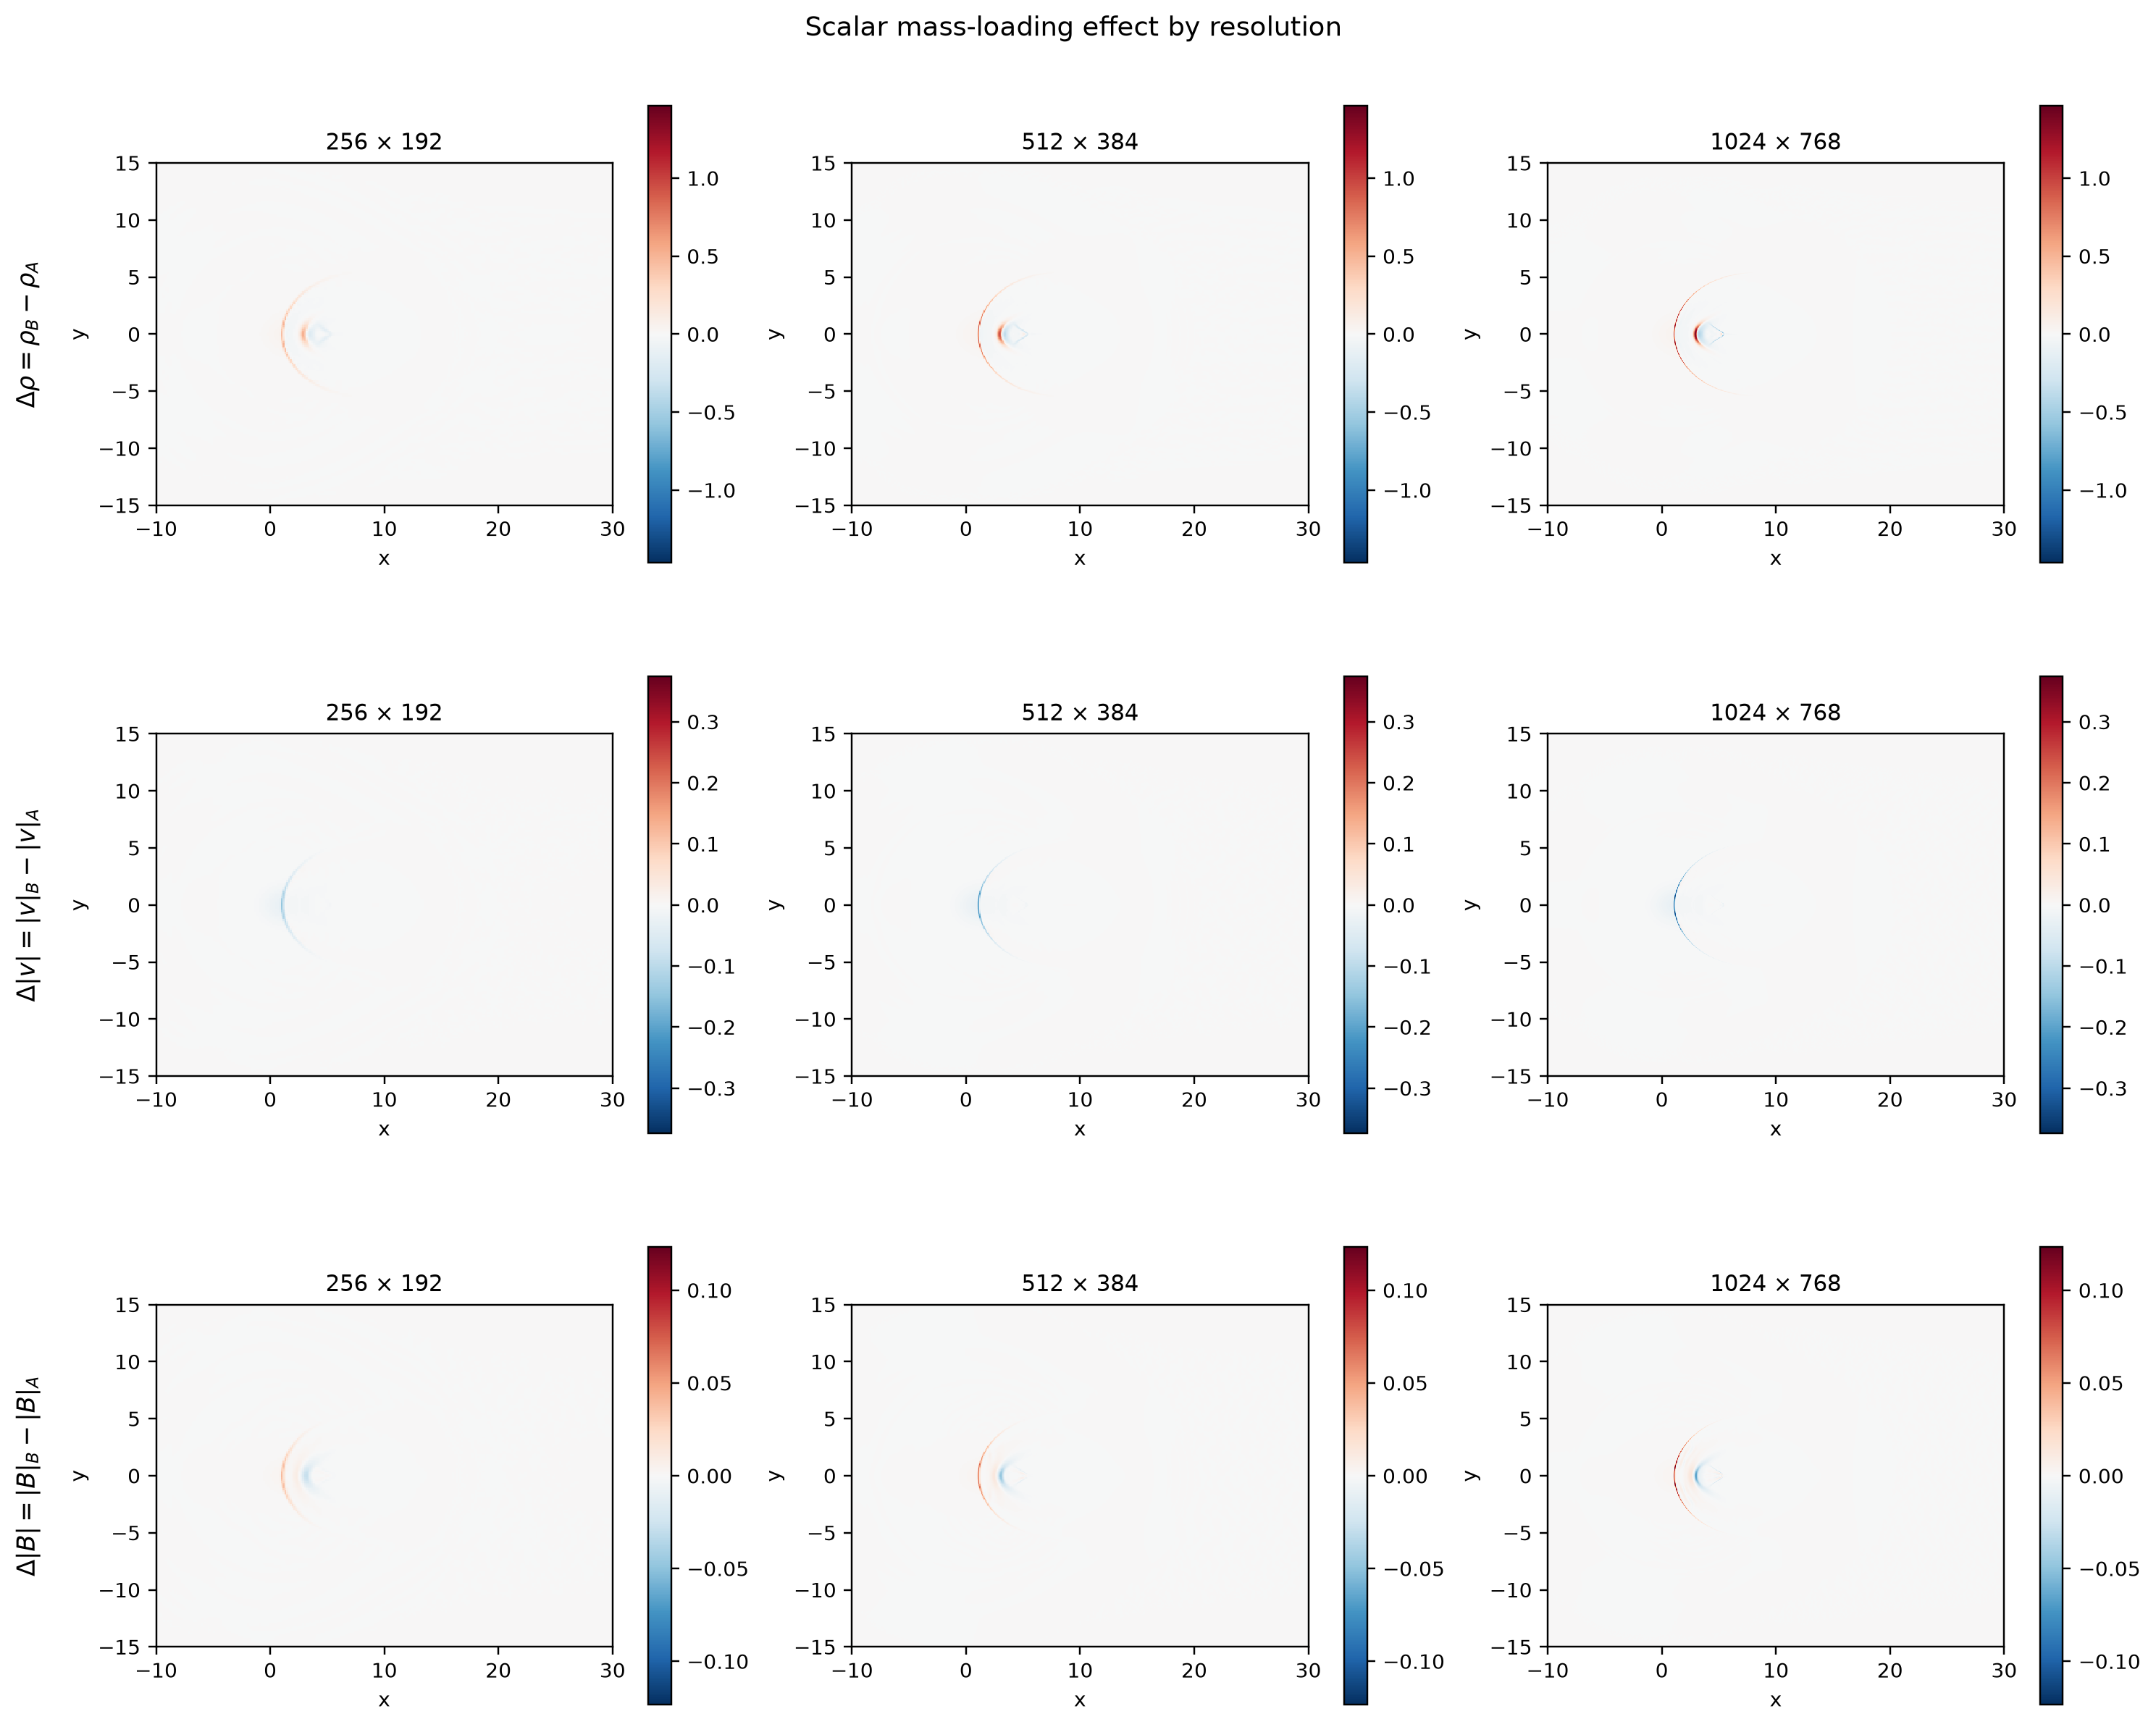

fig_errores_efecto_256_512.png


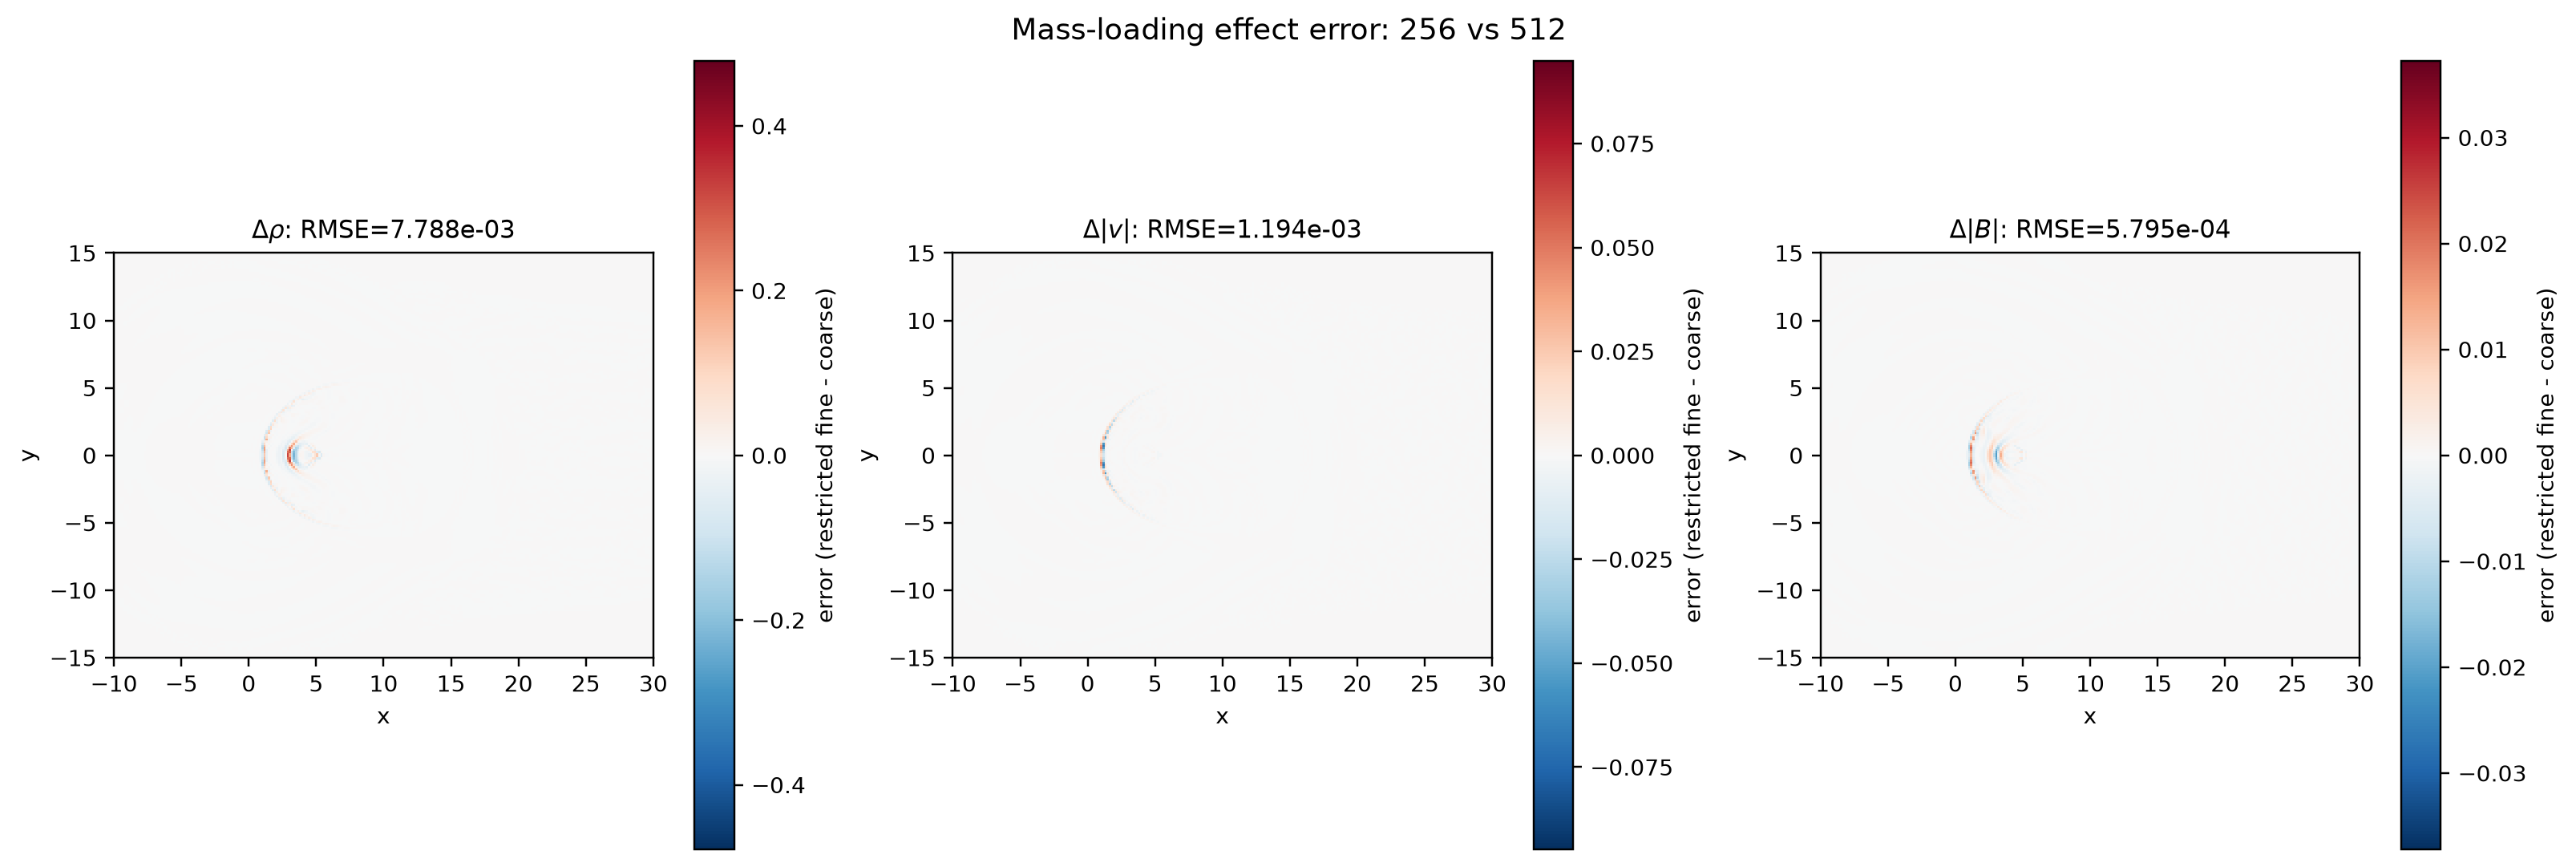

fig_errores_efecto_512_1024.png


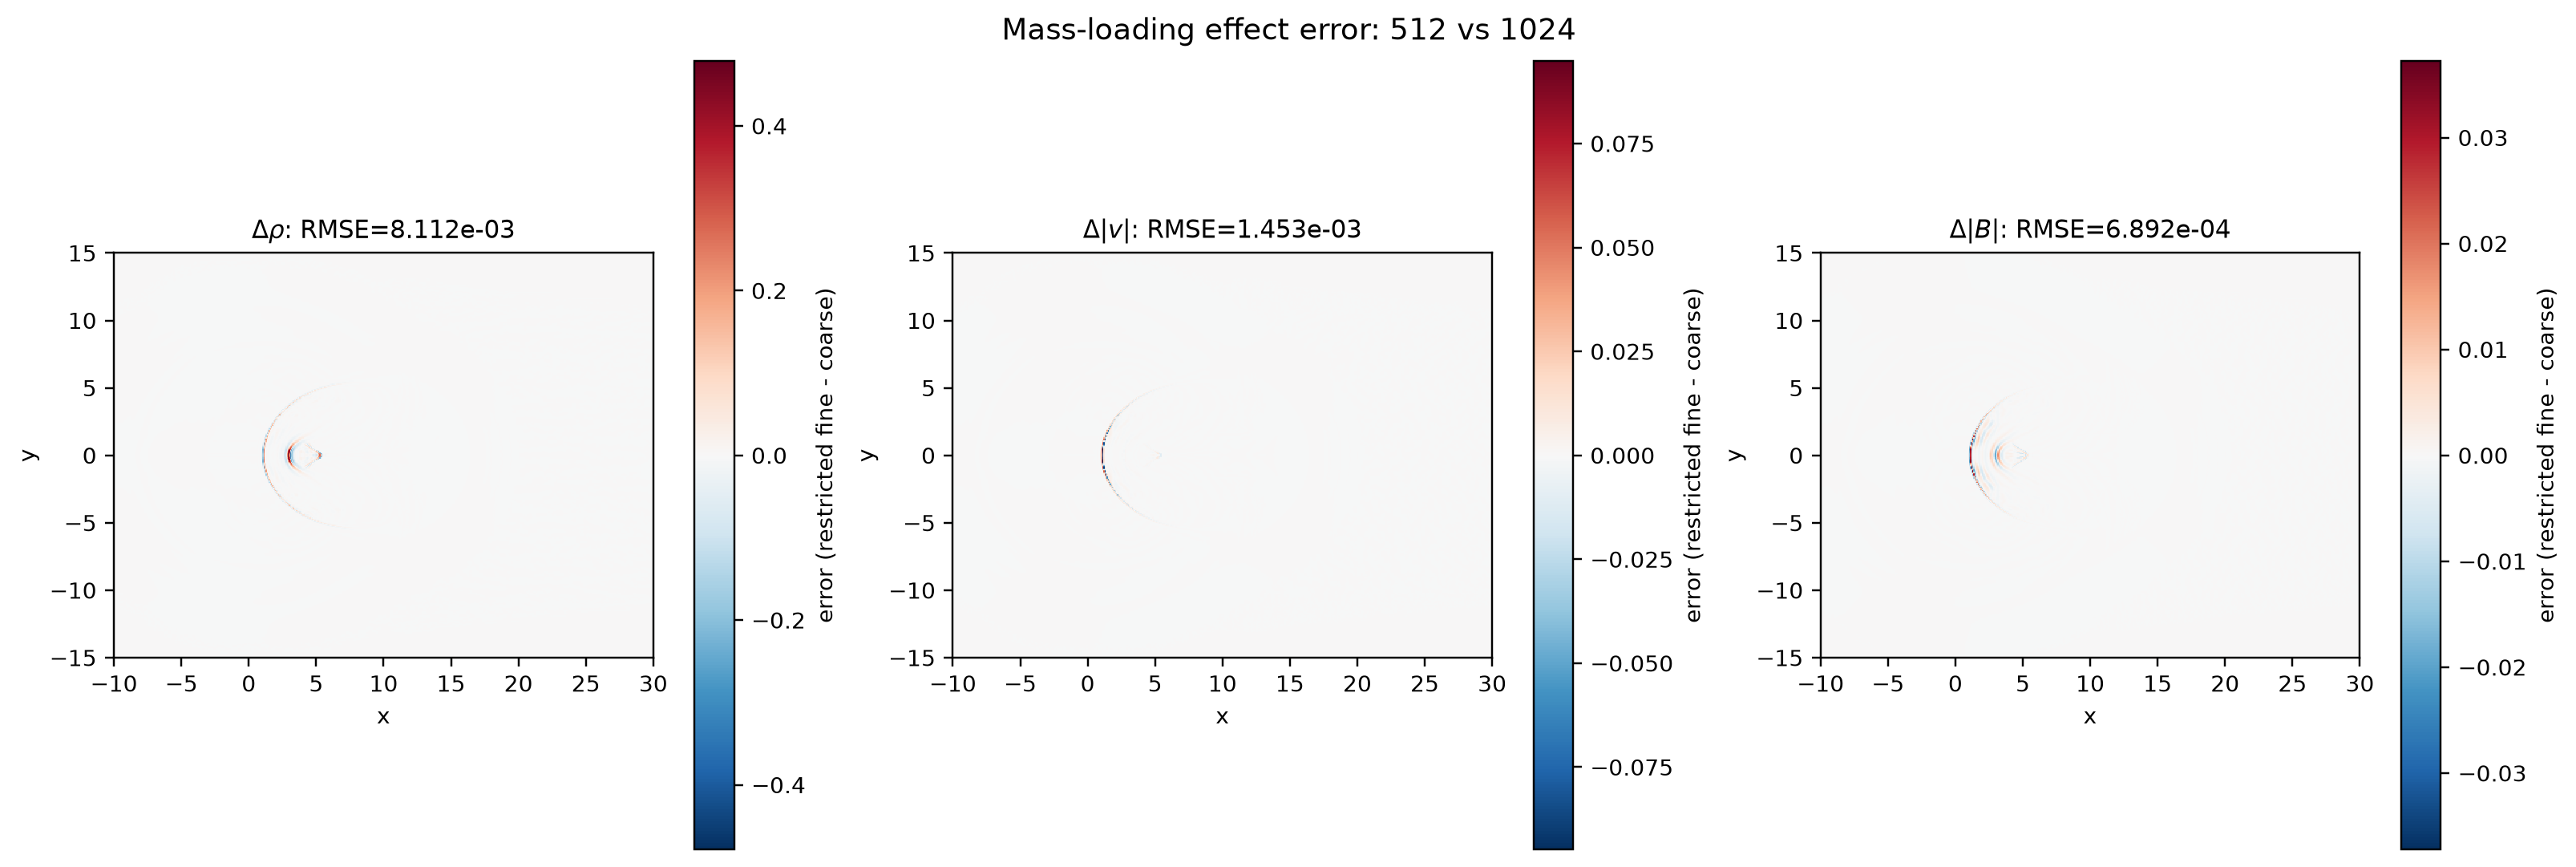

fig_rmse_global.png


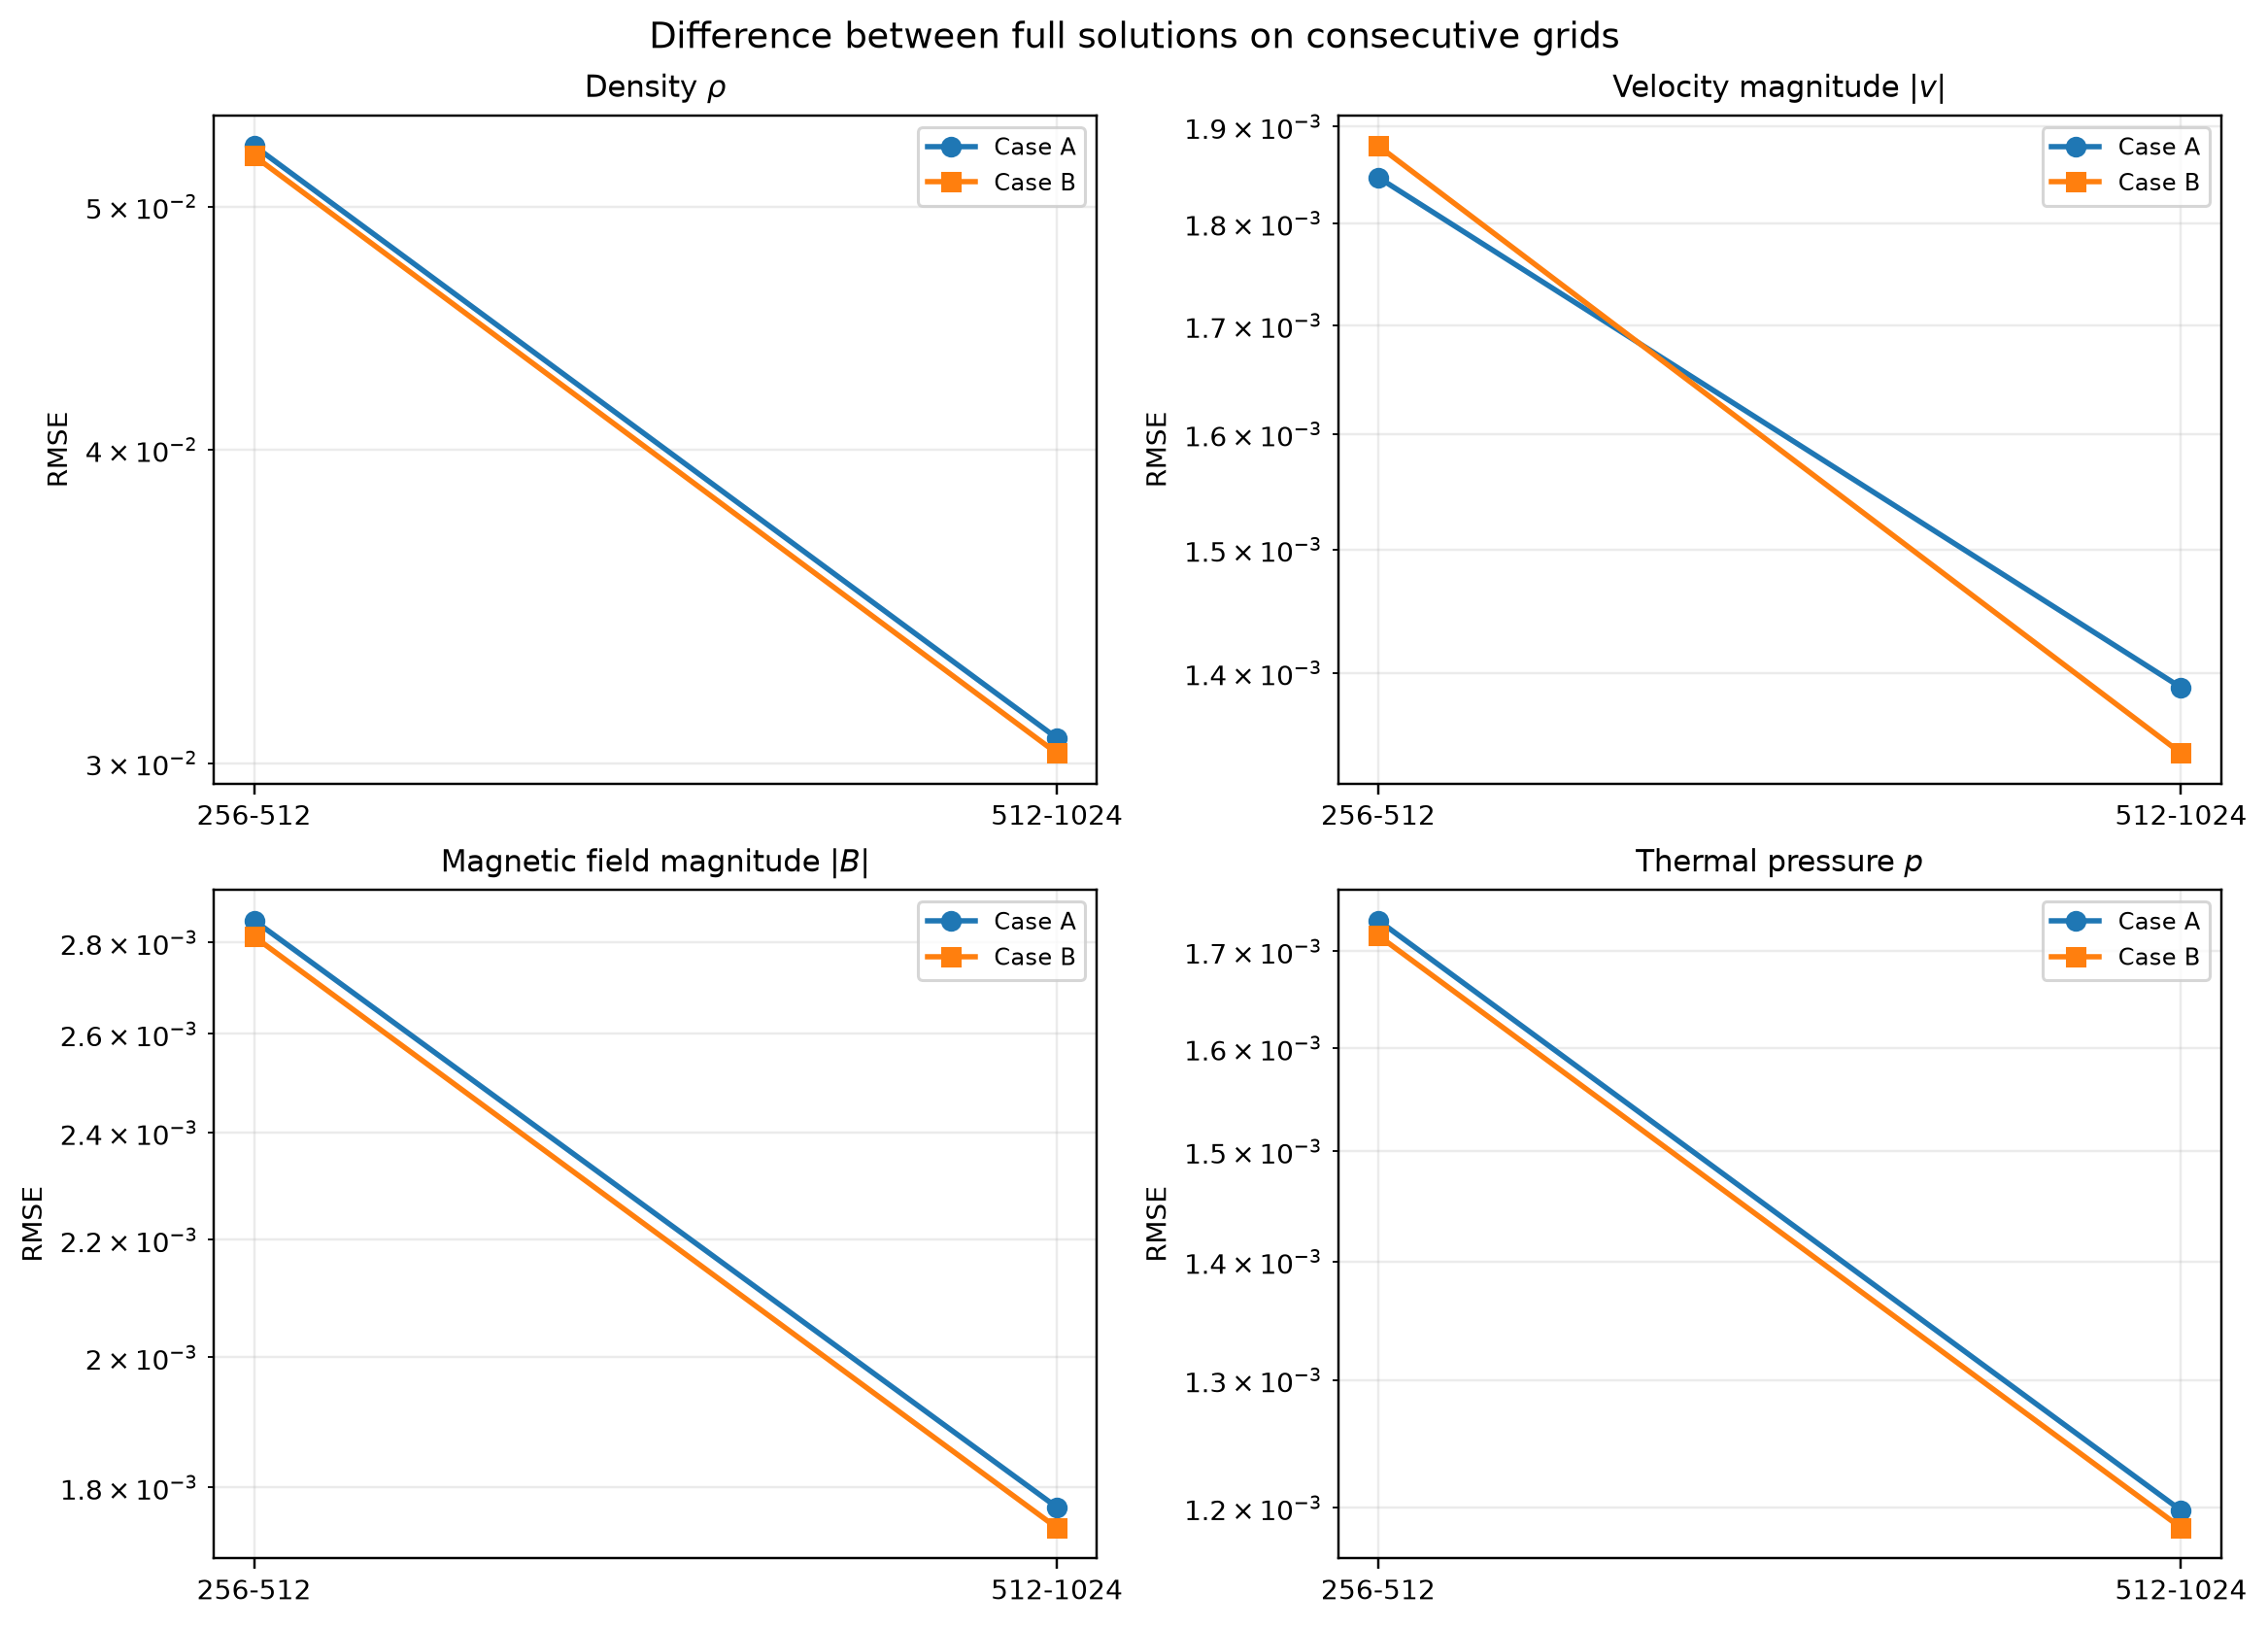

fig_rmse_efecto_roi.png


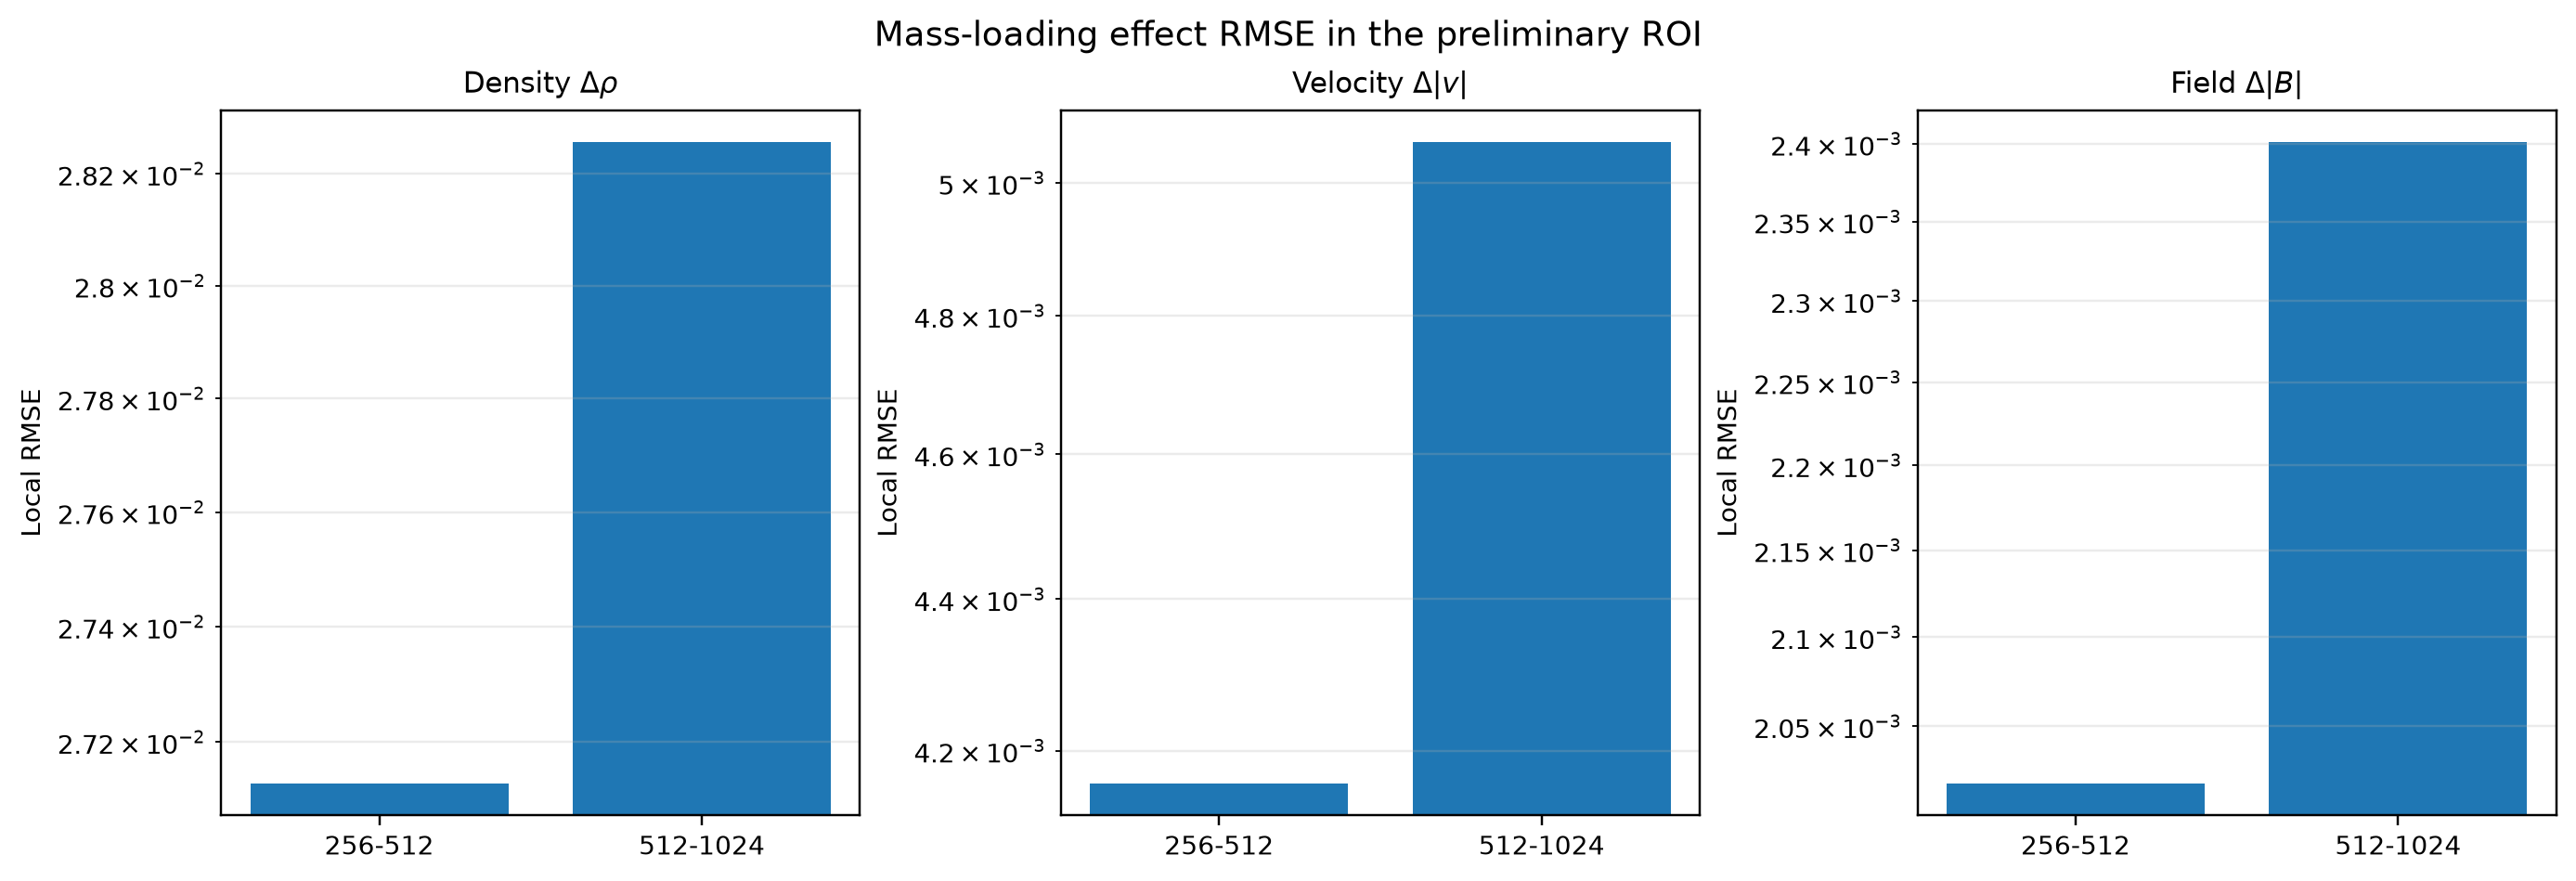

fig_concentracion_error.png


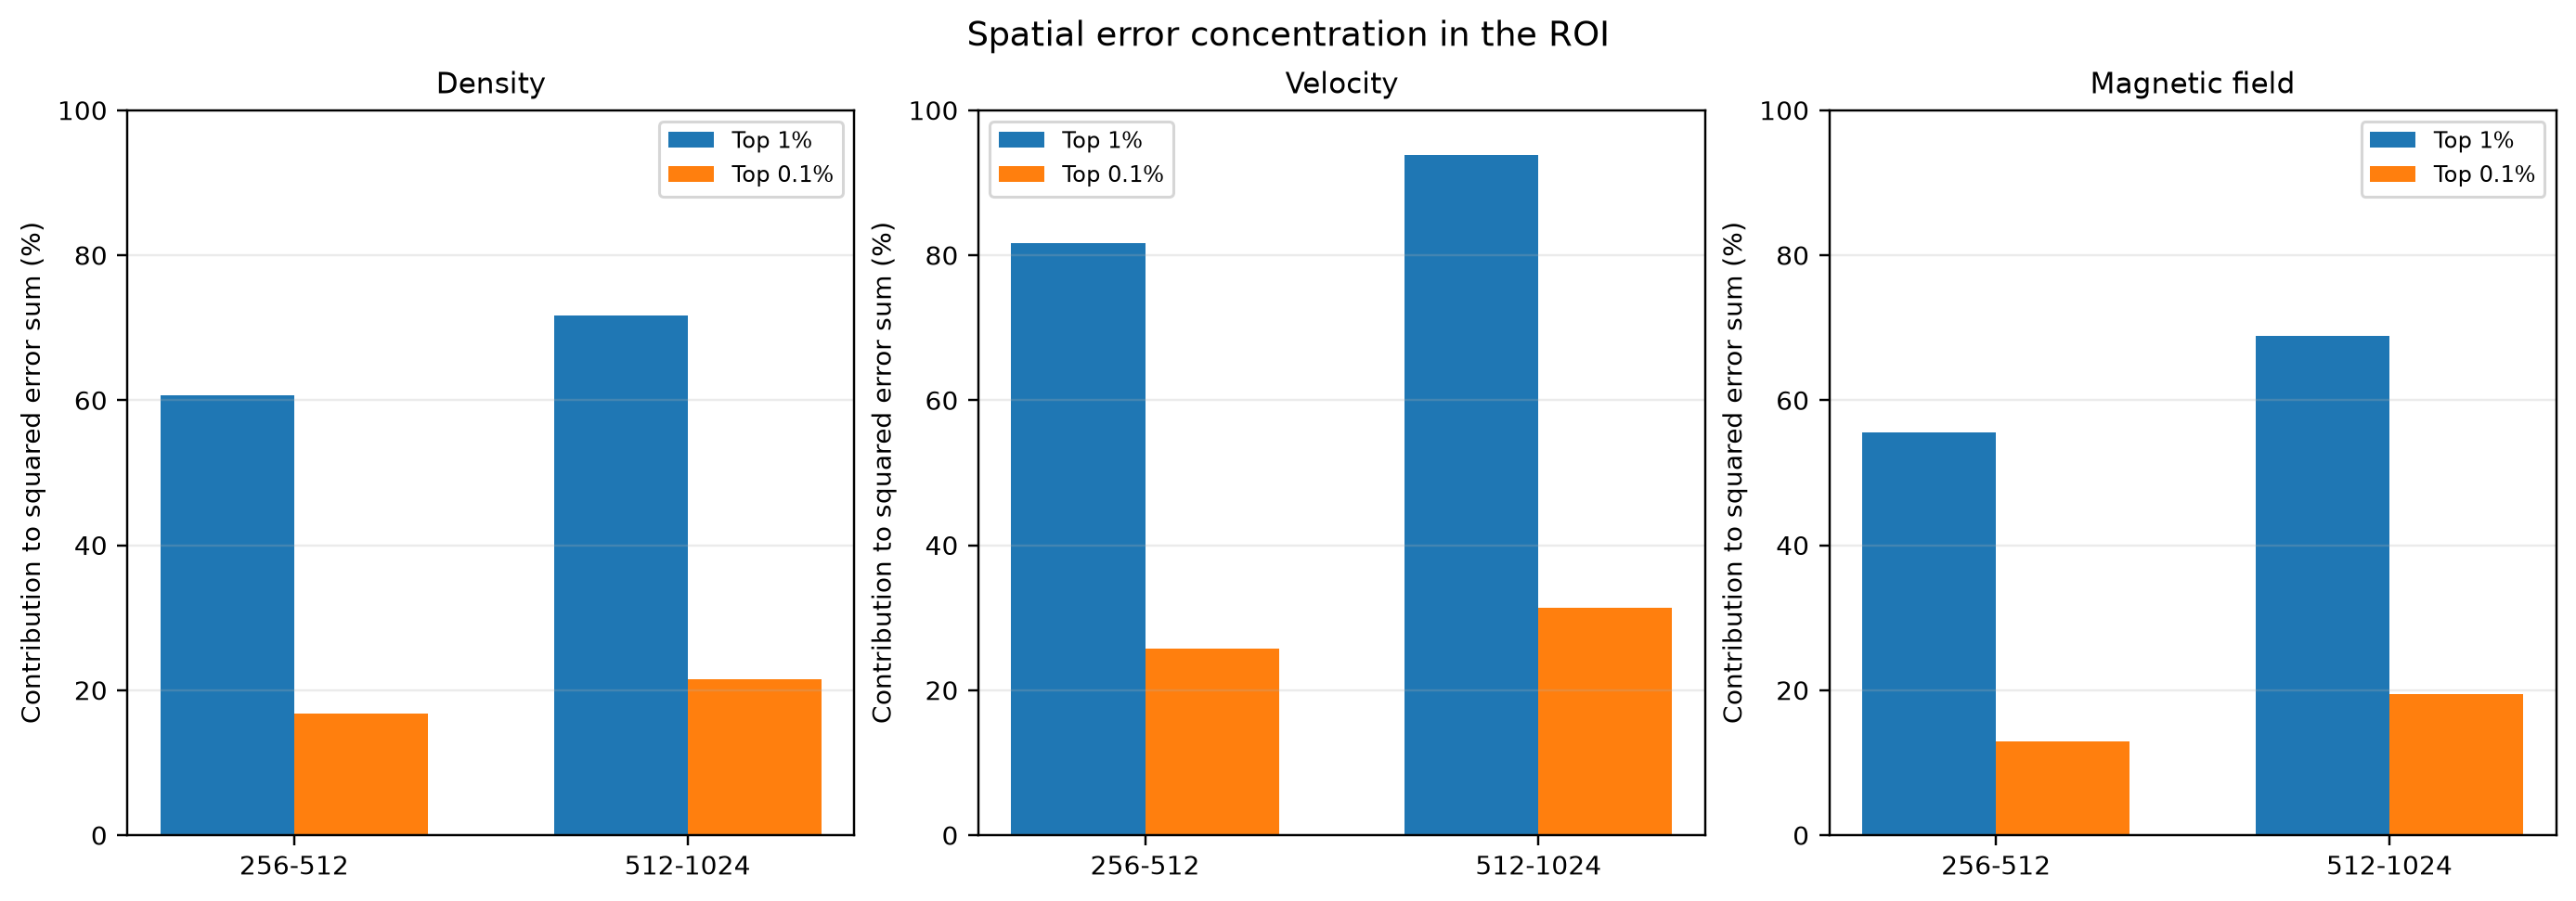

fig_localizacion_top_errores.png


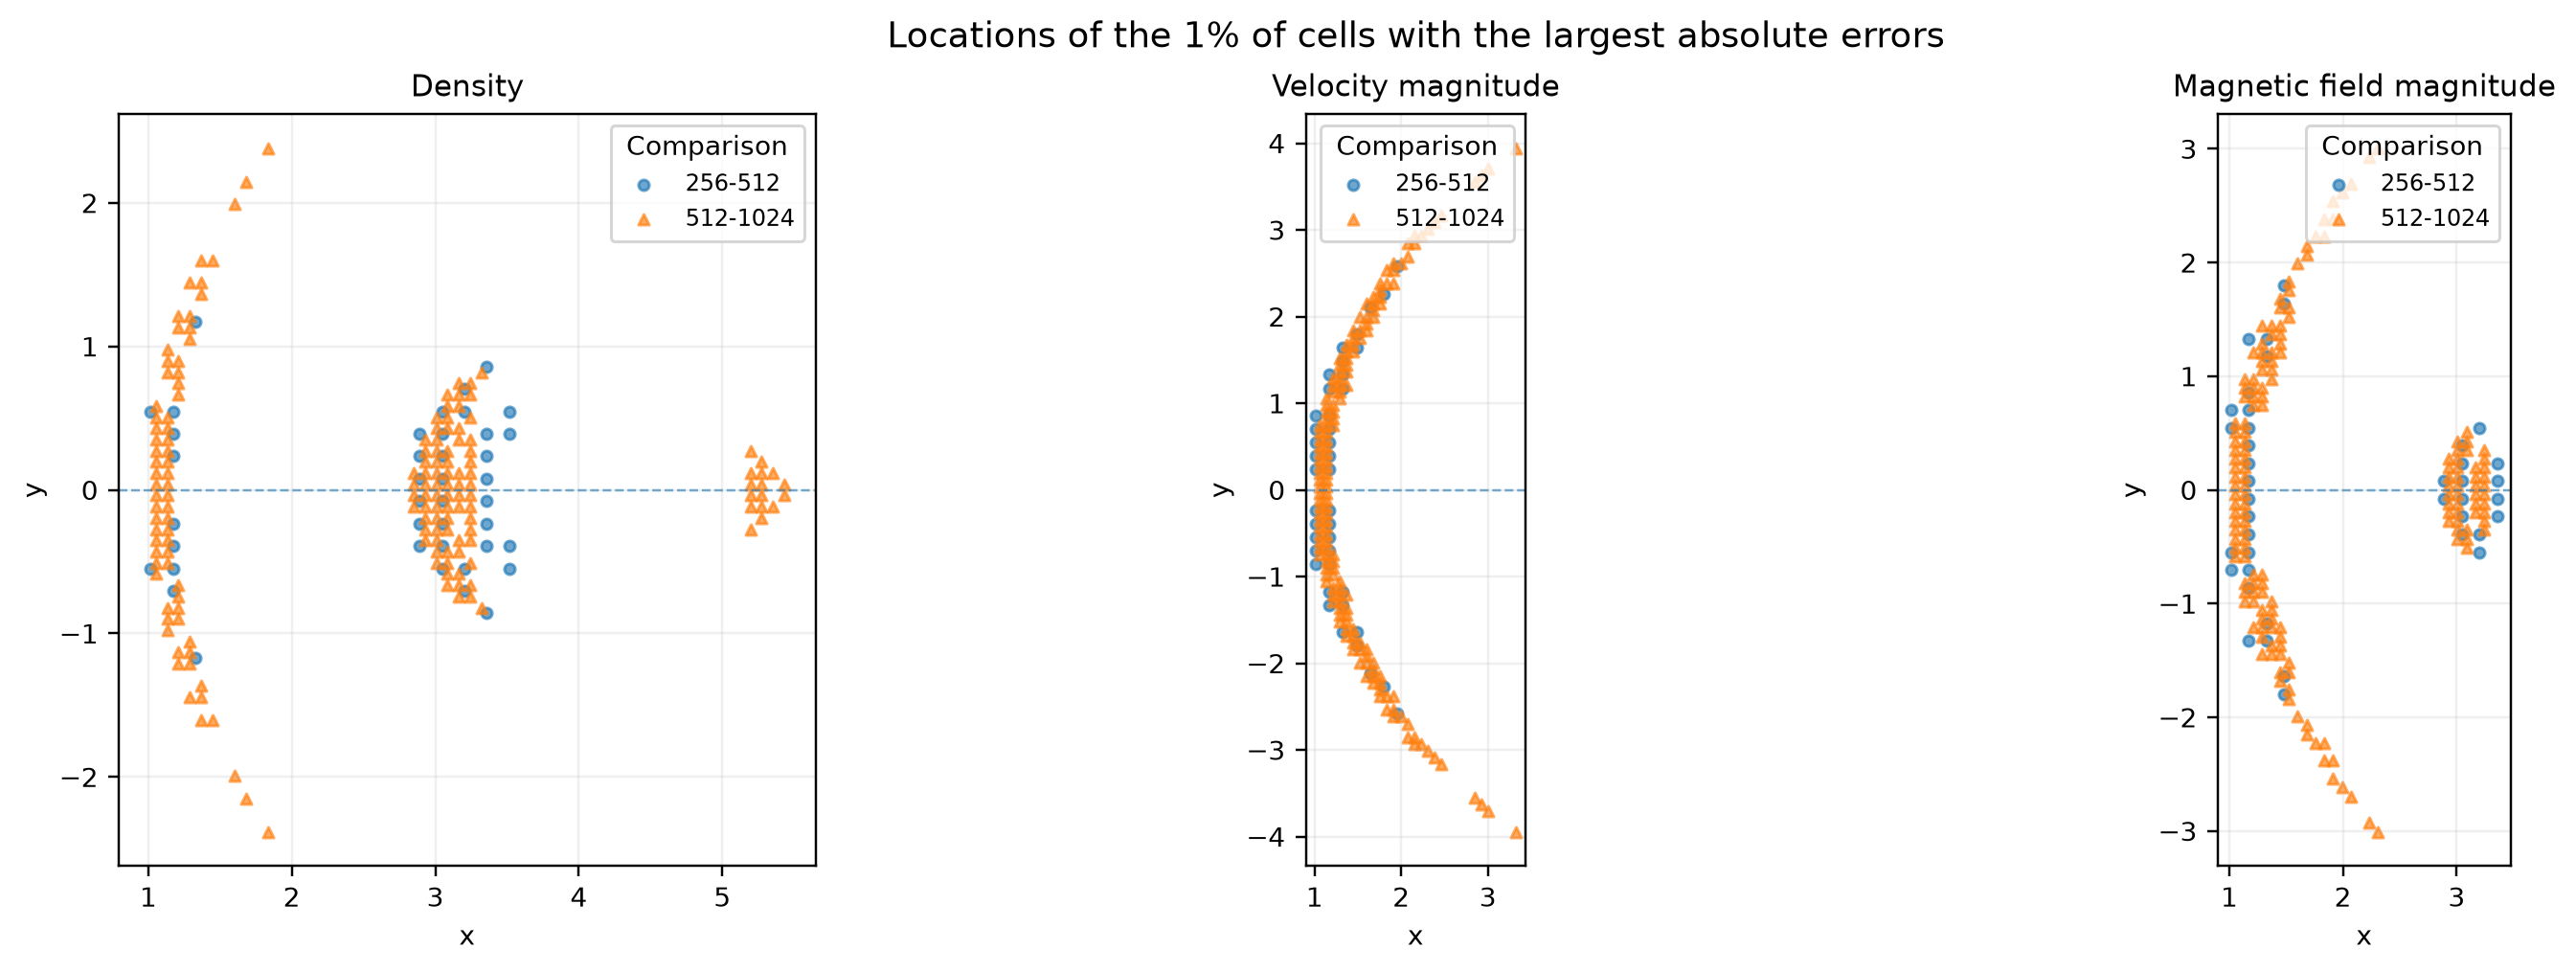

fig_balance_masa.png


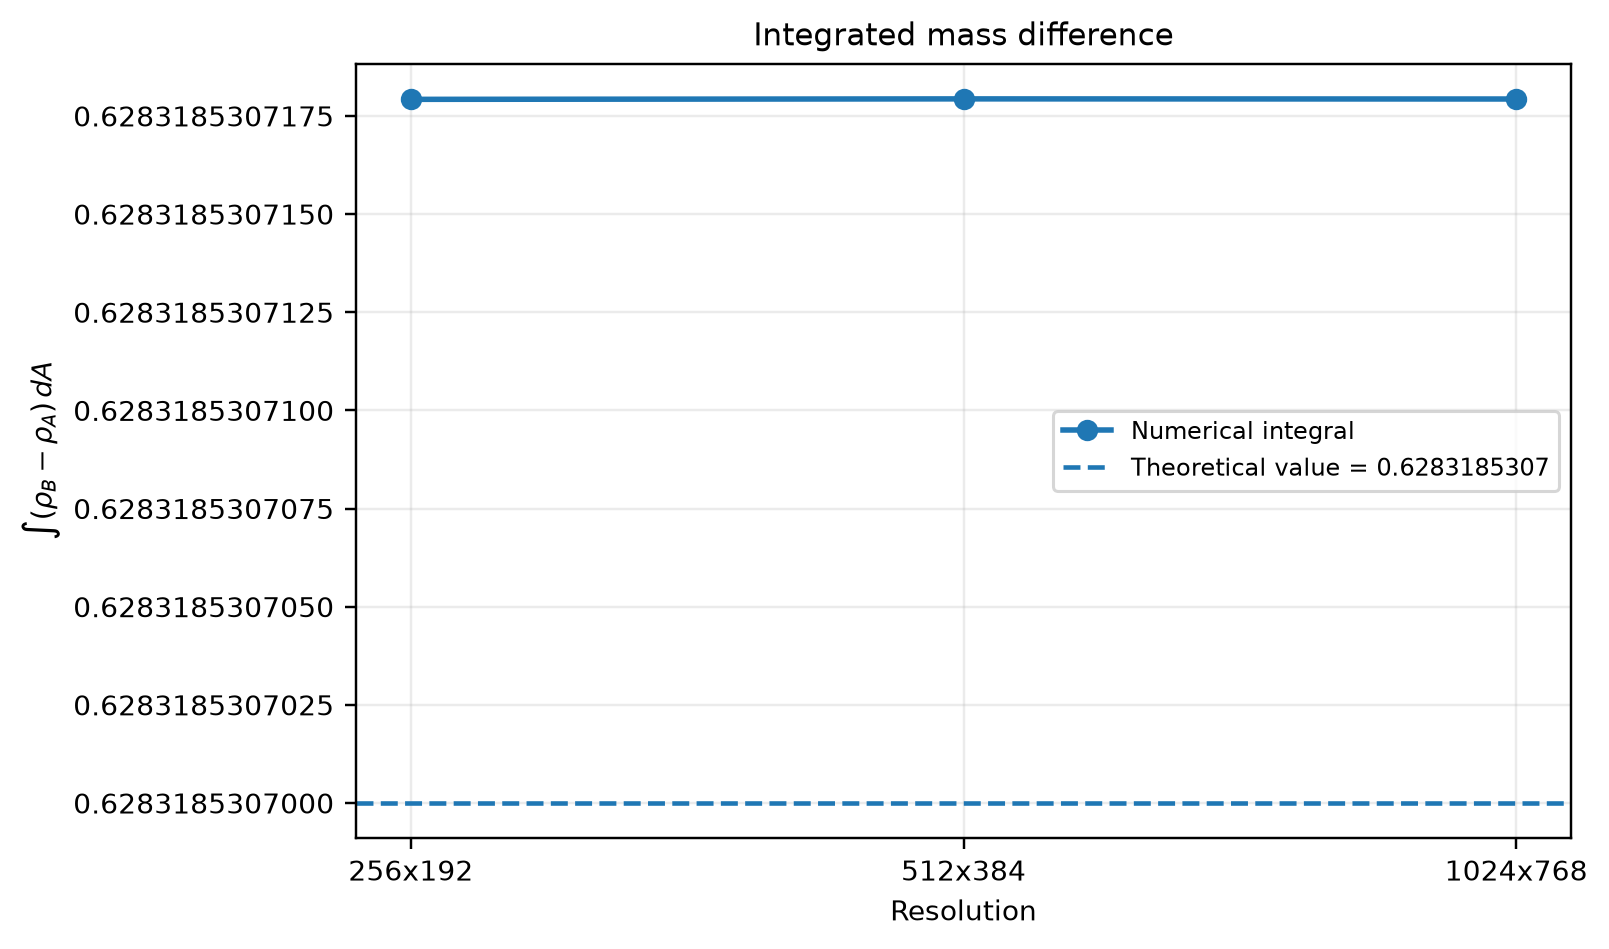

In [35]:
from IPython.display import display, Image

figure_names = [
    "fig_efectos_carga_masa.png",
    "fig_errores_efecto_256_512.png",
    "fig_errores_efecto_512_1024.png",
    "fig_rmse_global.png",
    "fig_rmse_efecto_roi.png",
    "fig_concentracion_error.png",
    "fig_localizacion_top_errores.png",
    "fig_balance_masa.png",
]

for name in figure_names:
    path = FIG_DIR / name
    if path.exists():
        print(name)
        display(Image(filename=str(path)))
    else:
        print(f"Not generated yet: {path}")


### **Inspect the Calculated Tables**

The CSV tables are saved in `resultados_convergencia/`. The following cell displays them directly in Jupyter.

In [30]:
import csv
from IPython.display import display, Markdown

for filename in [
    "metricas_soluciones_completas.csv",
    "metricas_efecto_carga_masa.csv",
    "balance_masa.csv",
    "orden_aparente_diagnostico.csv",
    "tiempos_salida.csv",
]:
    path = RESULT_DIR / filename
    if path.exists():
        print(f"\n{filename}")
        with path.open(encoding="utf-8", newline="") as stream:
            rows = list(csv.DictReader(stream))
        if rows:
            headers = list(rows[0].keys())
            header_line = "| " + " | ".join(headers) + " |"
            separator = "| " + " | ".join(["---"] * len(headers)) + " |"
            body = "\n".join(
                "| " + " | ".join(str(row.get(h, "")) for h in headers) + " |"
                for row in rows
            )
            display(Markdown("\n".join([header_line, separator, body])))



metricas_soluciones_completas.csv


| kind | case | pair | variable | n | mae | rmse | relative_l2_pct |
| --- | --- | --- | --- | --- | --- | --- | --- |
| full | A | 256-512 | rho | 49152 | 0.004241406190641028 | 0.05286436463263925 | 4.860045865087314 |
| full | A | 256-512 | speed | 49152 | 0.00024330581292874459 | 0.0018467049109744023 | 0.1869256910160251 |
| full | A | 256-512 | bmag | 49152 | 0.0002999868359886649 | 0.0028507499951675587 | 2.6442159624132255 |
| full | A | 256-512 | prs | 49152 | 0.00018027309135148118 | 0.0017332130840925913 | 3.1200164261597503 |
| full | B | 256-512 | rho | 49152 | 0.004192402006200352 | 0.05237583267856139 | 4.811540403871894 |
| full | B | 256-512 | speed | 49152 | 0.00024234907469135826 | 0.001879647104822226 | 0.19030512761363302 |
| full | B | 256-512 | bmag | 49152 | 0.0002972788649665642 | 0.002813543081966104 | 2.6097313677462837 |
| full | B | 256-512 | prs | 49152 | 0.0001785820782519332 | 0.0017168881797877925 | 3.0808176972963084 |
| full | A | 512-1024 | rho | 196608 | 0.002068098215274464 | 0.030695557519975686 | 2.8025130361420434 |
| full | A | 512-1024 | speed | 196608 | 0.00011973606190939515 | 0.0013885529544083264 | 0.14053932692695492 |
| full | A | 512-1024 | bmag | 196608 | 0.00017032485540372273 | 0.0017711102847662097 | 1.640874661878761 |
| full | A | 512-1024 | prs | 196608 | 9.142223858193243e-05 | 0.0011980476158719871 | 2.153416494874937 |
| full | B | 512-1024 | rho | 196608 | 0.0020465095720411837 | 0.03027139078294641 | 2.762107789277109 |
| full | B | 512-1024 | speed | 196608 | 0.00011968539251493789 | 0.001338497992564286 | 0.13550552353378426 |
| full | B | 512-1024 | bmag | 196608 | 0.00016733695973796686 | 0.0017418768687850175 | 1.613866100739818 |
| full | B | 512-1024 | prs | 196608 | 9.043431358151391e-05 | 0.0011850645517238727 | 2.123524321318285 |


metricas_efecto_carga_masa.csv


| variable | pair | global_mae | global_rmse | global_relative_l2_pct | roi_mae | roi_rmse | roi_relative_l2_pct | p50 | p95 | p99 | top1_sq_pct | top01_sq_pct | max_abs_roi | max_x | max_y | roi_cells |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| rho | 256-512 | 0.0006569894051212634 | 0.007788235103084914 | 47.70802351316477 | 0.007871948182691147 | 0.027128909309128747 | 37.42240218627137 | 0.0003087871889888294 | 0.03971964490614713 | 0.13875180209992866 | 60.62432600254066 | 16.73230652466156 | 0.3247585817751346 | 2.890625 | -0.078125 | 4050 |
| speed | 256-512 | 7.20852885483146e-05 | 0.0011937057022735496 | 35.79121079513629 | 0.00085965162920983 | 0.004158311742949417 | 32.72091732195141 | 4.4474163035629344e-05 | 0.002276749959079159 | 0.02114885940144 | 81.61900690905983 | 25.781950997549277 | 0.06732715508158346 | 1.171875 | -0.703125 | 4050 |
| bmag | 256-512 | 5.295835361901846e-05 | 0.0005795098111140746 | 48.42767042381465 | 0.0006328359277123516 | 0.0020186483121615883 | 39.48255332139949 | 5.0102538695633025e-05 | 0.003193245082362221 | 0.010289955752244399 | 55.599040449329664 | 12.936189550279606 | 0.02116896676802748 | 1.171875 | -0.546875 | 4050 |
| rho | 512-1024 | 0.0005327002076438588 | 0.008112045533399215 | 34.77888074570287 | 0.006394716566087982 | 0.028256269533046538 | 29.383235435159882 | 6.324633590468198e-05 | 0.026795538084406413 | 0.15349077222304994 | 71.7185807192896 | 21.56089251395471 | 0.47834890258240526 | 2.9296875 | -0.0390625 | 16200 |
| speed | 512-1024 | 6.312101949592653e-05 | 0.001453246714913405 | 34.45015188015526 | 0.0007570556860527196 | 0.0050626055812469884 | 30.50309748321288 | 1.0973563555907728e-05 | 0.0014782789356560411 | 0.016963850002923466 | 93.86109752709142 | 31.413937753925232 | 0.09478274868817338 | 1.1328125 | 0.4296875 | 16200 |
| bmag | 512-1024 | 5.1161592244130806e-05 | 0.0006891964355955027 | 42.8885773653107 | 0.0006168735004043653 | 0.0024009321565153056 | 36.088617969980376 | 2.047235159229055e-05 | 0.0030252341713255626 | 0.011945992864175052 | 68.84485175950712 | 19.424307468347855 | 0.03720127115866885 | 1.2109375 | 0.8984375 | 16200 |


balance_masa.csv


| resolution | integrated_mass_difference | theoretical_value | relative_difference_pct |
| --- | --- | --- | --- |
| 256x192 | 0.628318530717924 | 0.6283185307 | 2.852692503130855e-09 |
| 512x384 | 0.628318530717936 | 0.6283185307 | 2.8546008359397878e-09 |
| 1024x768 | 0.6283185307179326 | 0.6283185307 | 2.8540707434928618e-09 |


orden_aparente_diagnostico.csv


| variable | rmse_256_512 | rmse_512_1024 | diagnostic_apparent_order |
| --- | --- | --- | --- |
| rho | 0.027128909309128747 | 0.028256269533046538 | -0.0587399631899373 |
| speed | 0.004158311742949417 | 0.0050626055812469884 | -0.2838821716500158 |
| bmag | 0.0020186483121615883 | 0.0024009321565153056 | -0.25020505070680654 |


tiempos_salida.csv


| simulation | time |
| --- | --- |
| A256 | 10.0 |
| B256 | 10.0 |
| A512 | 10.0 |
| B512 | 10.0 |
| A1024 | 10.0 |
| B1024 | 10.0 |

## C/2023 A3 (Tsuchinshan–ATLAS): PLUTO MHD Simulation

### **Ephemeris and upstream solar-wind state**



A JPL Horizons query was made for C/2023 A3 at 2024-10-10 12:54 UTC.

Heliocentric ecliptic position:
$$
\mathbf r=(0.499055328,\;0.137594360,\;0.047987181)\;\mathrm{AU}
$$

Heliocentric velocity:
$$
\mathbf v=(35.17073698,\;-30.22329042,\;35.53058265)\;\mathrm{km\,s^{-1}}
$$

Heliocentric distance: $r_h=0.519895372$ AU. Orbital speed: 58.41960567 km/s.

The solar-wind radial speed was assumed to be 400 km/s. In the comet-relative local frame, the flow is:
$$
\mathbf V_{rel}=(374.405605,\;0,\;0)\;\mathrm{km\,s^{-1}}
$$

A Parker-spiral field was estimated assuming a 7 nT field at 1 AU and a solar rotation period of 25.38 days. In the local simulation frame:
$$
\mathbf B=(16.49881045,\;-11.55839307,\;1.56963317)\;\mathrm{nT}
$$
with magnitude about 20.2057 nT. The assumed solar-wind density at the comet was 18.49856762 cm^-3.

**Caveat:** these are model-derived upstream conditions, not in-situ measurements at the comet for that exact time.

### **Code-unit normalization and initialized state**



| Scale | Value |
|---|---:|
| Length, L0 | 1.0 × 10^11 cm = 1.0 × 10^6 km |
| Velocity, V0 | 4.0 × 10^7 cm/s = 400 km/s |
| Time, T0 | 2.5 × 10^3 s |
| Density, rho0 | 3.09411097591 × 10^-23 g/cm³ |
| Magnetic field, B0 | 78.87381846 nT |

Dimensionless upstream state:
- density = 1.0
- velocity = (0.936014013, 0, 0)
- pressure = 0.01032
- magnetic field = (0.20917981, -0.14654284, 0.01990056)
- initial tracer = 0

The pressure used the adopted equal proton/electron temperature assumption of 10^5 K.

### **Neutral coma and mass-loading model**



The neutral density was represented with a Haser-type profile:
$$
n_n(r)=\frac{Q}{4\pi V_n r_{eff}^{2}}\exp(-r/L_i),
\qquad r_{eff}=\sqrt{r^2+r_{soft}^2}
$$

Adopted parameters:
- production rate: $Q=10^{29}$ molecules/s (assumption);
- neutral speed: $V_n=0.7$ km/s;
- ionization frequency: $\nu_i=3.06\times10^{-6}$ s^-1;
- ionization length: $L_i=V_n/\nu_i\approx2.2876\times10^{10}$ cm (about 228,758 km);
- softening radius: $r_{soft}=1.2\times10^9$ cm (12,000 km);
- representative ion mass: $m_i=18m_p$, representing H2O+.

Mass injection is $S_\rho=m_i\nu_i n_n$. Conservative source terms add mass, momentum $S_\rho\mathbf u_n$, and energy $S_\rho(\epsilon_n+|\mathbf u_n|^2/2)$. The tracer source is set equal to the mass source.

**Limitations:** this is a 2D planar slice of a 3D coma, invariant in the omitted direction. Its 2D integral is not the global 3D production rate. Detailed pickup-ion heating, electron/ion thermodynamics, and additional chemistry are not represented in this simplified prescription.

### **Solver configuration and code modifications**



Reported configuration:
- 2D Cartesian MHD; ideal-gas EOS;
- RK2 time stepping;
- flat reconstruction; MC limiter;
- GLM divergence cleaning (`DIV_CLEANING`);
- one passive tracer;
- HLL Riemann solver;
- 256 × 256 grid;
- x1 domain [-0.5, 2.5], x2 domain [-1.0, 1.0];
- x1 lower boundary: user-defined solar-wind inflow; x1 upper: outflow;
- x2 boundaries: outflow; x3: periodic with one cell.

The case Makefile points to `/PLUTO-comet`. The original `/PLUTO` tree was kept unchanged. A `local_make` file was used to include the GLM object:
```make
VPATH += $(SRC)/MHD/GLM
OBJ += glm.o
```

`init.c` initializes uniform solar-wind density, velocity, pressure, magnetic field, zero GLM scalar, and zero tracer. `UserDefBoundary()` applies the same upstream state at the left x1 boundary.

In `PLUTO-comet/Src/MHD/rhs_source.c`, the comet source block is guarded for Cartesian MHD and applied only during the IDIR sweep. It calls `EvaluateCometSource(x1[i], x2[j])` and adds:
- `dt * srho` to density;
- `dt * srho * unx` and `dt * srho * uny` to x1/x2 momentum;
- `dt * energy` to total energy when enabled;
- `dt * srho` to the tracer when a tracer exists.

The inspected block was around lines 255–286.

### **Simulation variants and execution history**

#### C0 — baseline without comet mass loading
The source was disabled using `COMET_QM0 = 0.0` in the then-current case configuration. C0 completed and was archived in:
`C2023A3_20241010_1254/C0_256/`

C0 output inspection showed uniform values: rho=1, vx1=0.936014013, vx2=vx3=0, pressure=0.01032, GLM scalar=0, tracer=0. This validated the uniform upstream initialization.

#### C1 — Haser mass-loading source enabled
C1 compiled successfully in:
`C2023A3_20241010_1254/C1_256/`

It was run but manually interrupted after a negative-pressure warning at step 4975, RK stage 2, at code time about 11.807. The warning location was reported as [i,j]=[70,257], [x1,x2]=[0.302734,0.996094], with a very large Mach number. The requested `tstop` was 16. The last `dbl.out` record shown was at code time 10.30872; this differs from the warning time because output records are not written every time step.

### **C1 output statistics and pressure-floor analysis**

For C1 output 1, PyPLUTO reported:

| Field | Minimum | Maximum | Mean |
|---|---:|---:|---:|
| rho | 0.565457876 | 76.9662784 | 2.20120492 |
| vx1 | 0.08640175 | 1.01839217 | 0.615272356 |
| vx2 | -0.427618087 | 0.335288718 | 0.0335733958 |
| vx3 | -0.0193102349 | 0.0164506661 | -0.00220185733 |
| pressure | 1.0e-12 | 0.675943095 | 0.07425688 |
| GLM scalar | -0.0771448381 | 0.0976599940 | 0.00928959249 |
| tracer | 6.63614186e-6 | 0.997060265 | 0.253901364 |

There were 2,800 pressure-floor cells out of 65,536:
\[
100\frac{2800}{65536}=4.2724609375\%
\]

The pressure floor is `g_smallPressure = 1.e-12` in `Src/globals.h`. In the MHD conservative-to-primitive mapper, negative pressure computed from total energy is replaced by this floor, and the energy is recomputed. Therefore, floor cells flag a problematic conservative energy state; the floor is not a physical pressure result.

The pressure-floor cells occurred in both lower-left and upper-right regions:
- lower-left: 1,087 cells;
- upper-right: 1,713 cells.

### **Energy and source-term diagnostics**



The whole-domain means from `diagnose_energy.py` were:
- density: 2.201205;
- pressure: 0.07425688;
- kinetic-energy diagnostic: 0.3756991;
- magnetic-energy diagnostic: 0.1202099;
- magnetic-field magnitude: 0.4676776;
- plasma beta: 0.7636118;
- tracer: 0.2539014.

The lower-left pressure-floor region had low mean tracer (about 0.00328), while the upper-right region had much higher mean tracer (about 0.28738). Thus pressure-floor cells occur both where cometary tracer is scarce and where it is abundant. The issue cannot be attributed only to strong local mass injection.

`diagnose_source_cells.py` reported:

| Region | Mean source Sρ | Mean Sρ/rho | Mean dt·Sρ/rho |
|---|---:|---:|---:|
| Lower-left floor cells | 0.0036342 | 0.0037925 | 8.4392e-6 |
| Upper-right floor cells | 3.0689e-6 | 3.0451e-6 | 6.7760e-9 |
| All floor cells | 0.0014127 | 0.0014742 | 3.2804e-6 |

Across the whole domain, maximum source was about 509.11 at the nucleus and maximum Sρ/rho about 461.94. Using the last reported C1 time step 2.225228e-3 gives an estimated maximum fractional source increment of about 1.028 at the most strongly forced cell.

**Interpretation:** the source is stiff close to the nucleus, but pressure-floor cells have small local source increments. This makes a time-step sensitivity test worthwhile, but does not establish that source stiffness is the sole cause.

### **Results**

In [38]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pyPLUTO as pp

DIR = Path("C2023A3_20241010_1254")
CASE_DIR = DIR / "C1_256"
OUTPUT_NUMBER = 1
D = pp.Load(path=str(CASE_DIR) + "/", nout=OUTPUT_NUMBER)
print("Loaded:", CASE_DIR, "output:", OUTPUT_NUMBER)

def get_field(data, *names):
    for name in names:
        if hasattr(data, name):
            return np.asarray(getattr(data, name))
    raise AttributeError(f"Could not find any of: {names}. Inspect dir(D).")

rho = get_field(D, "rho", "Rho")
vx1 = get_field(D, "vx1", "Vx1")
vx2 = get_field(D, "vx2", "Vx2")
prs = get_field(D, "prs", "P")
tr1 = get_field(D, "tr1", "Tr1")

x1 = np.asarray(D.x1) if hasattr(D, "x1") else np.arange(rho.shape[1])
x2 = np.asarray(D.x2) if hasattr(D, "x2") else np.arange(rho.shape[0])
print("Field shape:", rho.shape)


Load: folder C2023A3_20241010_1254/C1_256/,     output 1
Loaded: C2023A3_20241010_1254/C1_256 output: 1
Field shape: (256, 256)


In [44]:
def plot_map(field, title, cbar_label, filename, log_scale=False,
             cmap="viridis", vmin=None, vmax=None, rotate_180=False,
             reflect_lr=False, invert_x=False):
    a = np.asarray(field)
    
    # Rotar 180° si está habilitado
    if rotate_180:
        a = np.rot90(a, k=2)
        
    # Reflejar de derecha a izquierda (espejo horizontal)
    if reflect_lr:
        a = np.fliplr(a)  # O también puedes usar a[:, ::-1]
        
    shown = np.log10(np.maximum(a, 1e-30)) if log_scale else a
    fig, ax = plt.subplots(figsize=(9, 5.5))
    m = ax.pcolormesh(x1, x2, shown, shading="auto", cmap=cmap,
                      vmin=vmin, vmax=vmax)
    
    # Invertir visualmente el eje X si se requiere
    if invert_x:
        ax.invert_xaxis()
        
    ax.set_xlabel("x1 (code units)")
    ax.set_ylabel("x2 (code units)")
    ax.set_title(title)
    cb = fig.colorbar(m, ax=ax)
    cb.set_label(("log10 " if log_scale else "") + cbar_label)
    fig.tight_layout()
    fig.savefig(DIR / filename, dpi=200, bbox_inches="tight")
    plt.close()

# Ejemplos de uso (con la rotación aplicada):
plot_map(rho, "C1: mass density", "rho", "C1_density.png", log_scale=True, rotate_180=True, reflect_lr=True)
plot_map(prs, "C1: thermal pressure", "pressure", "C1_pressure.png", log_scale=True, rotate_180=True, reflect_lr=True)
plot_map(tr1, "C1: cometary tracer", "tr1", "C1_tracer.png", vmin=0, vmax=1, rotate_180=True, reflect_lr=True)

speed = np.sqrt(vx1**2 + vx2**2)
plot_map(speed, "C1: in-plane speed", "|v|", "C1_speed.png", rotate_180=True, reflect_lr=True)

floor = prs <= 1.000001e-12
plot_map(floor.astype(float), "C1: pressure-floor mask",
         "floor-cell flag", "C1_pressure_floor_mask.png",
         cmap="gray_r", vmin=0, vmax=1, rotate_180=True, reflect_lr=True)

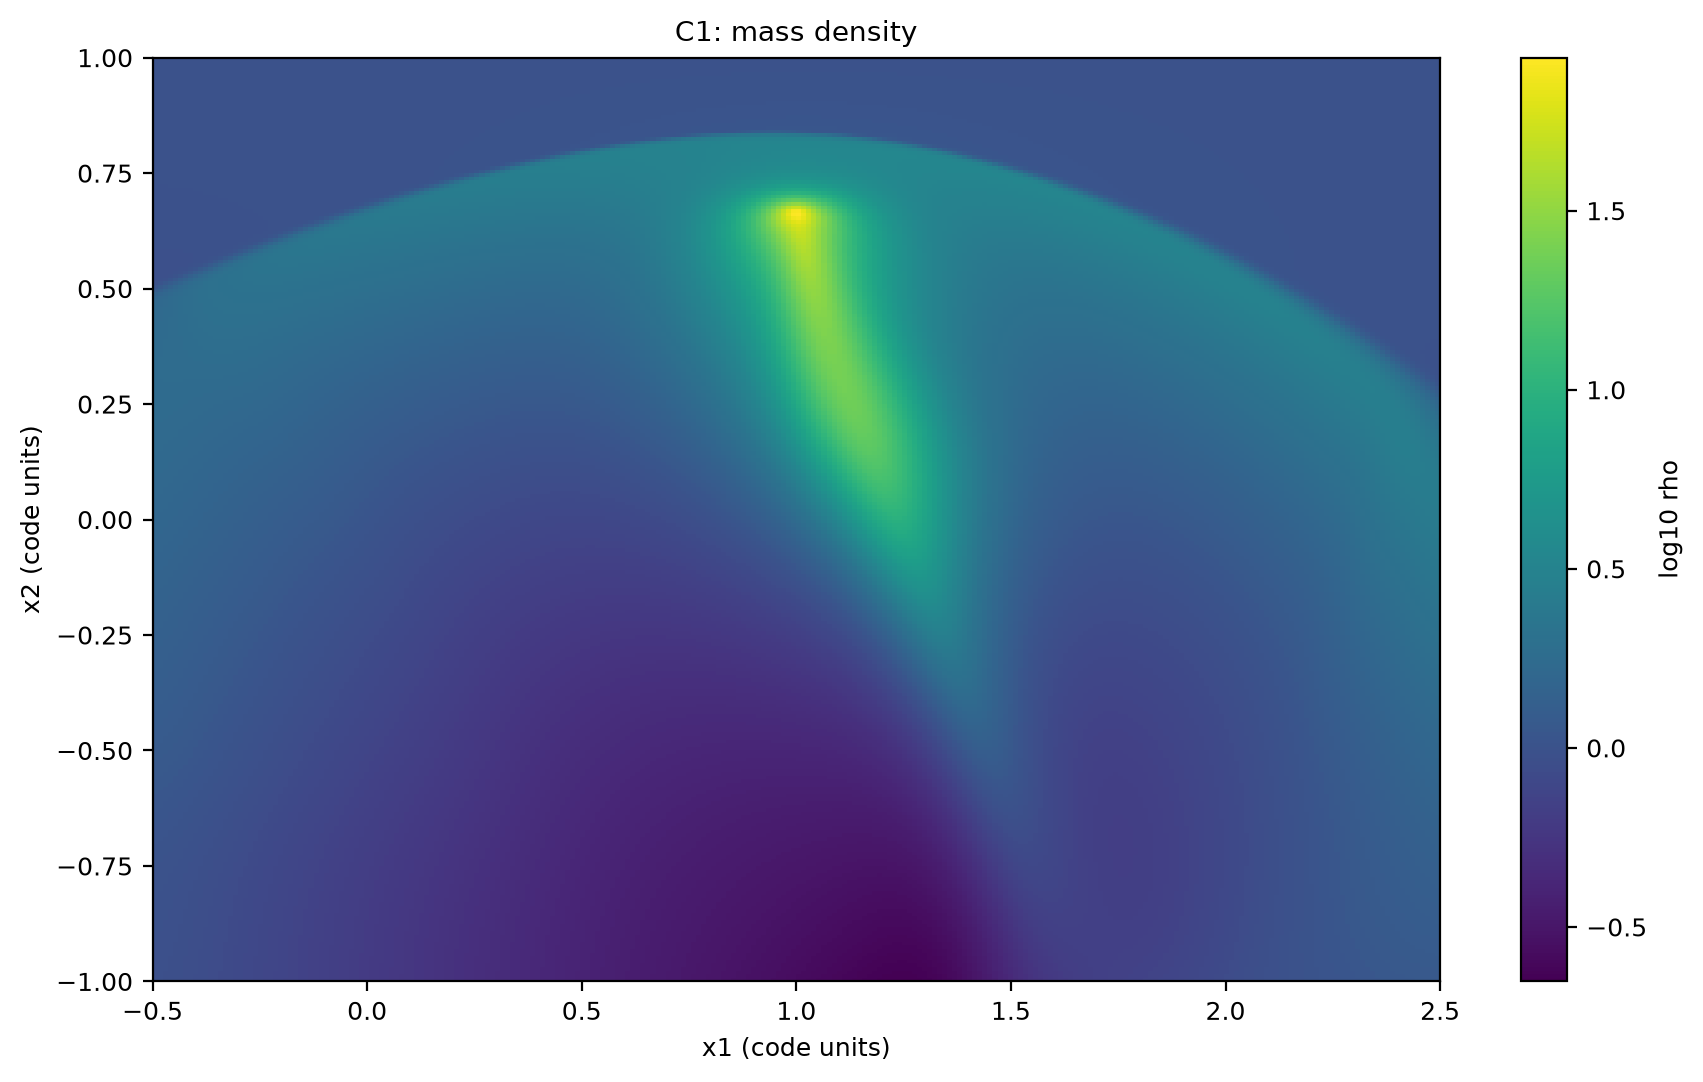

Simulation Result

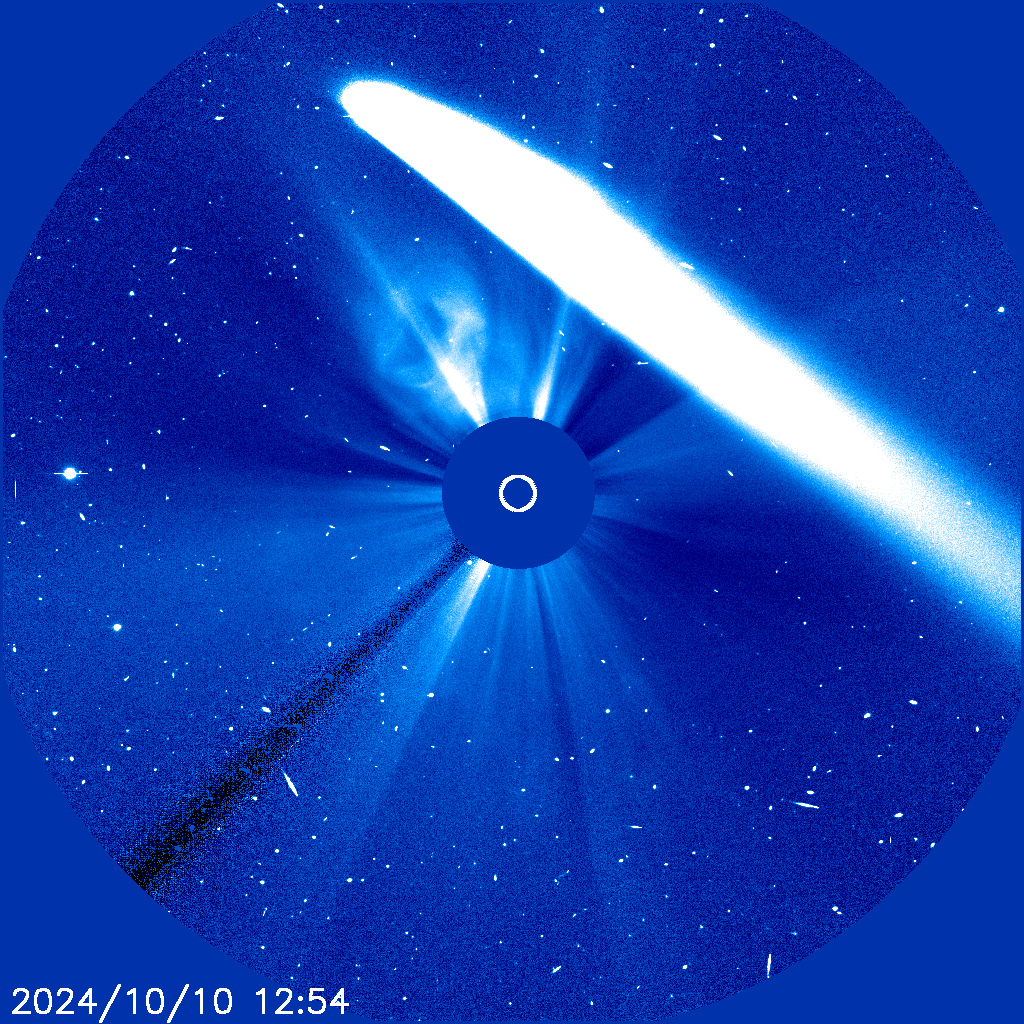

LASCO Imagery